# Multiclass (MEL vs BCC vs SCC): reducción de dimensionalidad con PCA y LDA

Igual que `03_v7_ml_multiclass_pca_lda.ipynb` pero con el remuestreo de `03_v4_ml_multiclass_smote.ipynb`:
**SMOTE de BCC y SCC hasta el nº de MEL** (no se quita ninguna imagen; mismos modelos y métricas) y lo único que cambia es **cómo se reducen las 412 features** antes del modelo. Se comparan en la
misma CV:

| Variante | Qué hace | ¿Supervisada? |
|---|---|---|
| `todas` | las 412 features | — |
| `top-K` | las K features más importantes según un Random Forest | sí |
| `PCA` | proyecta en las direcciones de **máxima varianza** (componentes = mezclas de features) | no |
| `LDA` | proyecta en las direcciones que **mejor separan las clases** (con 3 clases, máximo 2) | sí |

1. Carga de datos y **visualización con PCA y LDA**: varianza explicada, scatter 2D / 3D / matriz de los primeros
   componentes, loadings (qué features y familias pesan en cada componente) y proyección LDA de train y val.
2. CV estratificada de 5 folds en train con **todas las variantes de `REDUCTIONS` × todos los modelos**, más un resumen
   en heatmaps (kappa, balanced accuracy y recall de SCC).
3. Train vs CV y ablación por familias.
4. Evaluación final en **val** con la variante y el modelo que mejor salen en la CV, más una tabla **informativa** con el
   mejor modelo de cada variante en val (para ver si val confirma la CV, **no** para elegir).
5. Importancia por permutación y control de sesgo de adquisición.

**Dónde va cada paso (todo se ajusta solo con el train de cada fold):**

```
todas / top-K :  imputación → [top-K] → cuantil → SMOTE → modelo
PCA / LDA     :  imputación → cuantil → StandardScaler → PCA / LDA → SMOTE → modelo
```

- **El escalado tiene que ir antes de PCA/LDA.** PCA busca varianza; sin escalar, mandarían las features con valores
  más grandes por su unidad, no por su información. El cuantil (→ normal) ya deja casi todas las features con media 0 y
  desviación 1, y el `StandardScaler` lo garantiza exactamente, también en las features con muchos valores repetidos.
- **SMOTE:** en cada fold, solo en su train, se crean BCC y SCC **sintéticos** hasta tener tantos como MEL (SCC ×~7,
  BCC ×~1,4). Cada sintético es un punto al azar entre una muestra real y uno de sus 5 vecinos de la misma clase.
  Con PCA / LDA, SMOTE interpola en el espacio reducido, donde las distancias tienen más sentido que en 412 dimensiones.
- PCA y LDA se ajustan **antes** del remuestreo, con los datos reales, igual que el top-K. LDA usa *priors* iguales para que la proyección no la dicte el desbalance.
- PCA **no** usa las clases, así que puede conservar varianza que no discrimina. Suele ayudar a LogReg, SVM y KNN y
  perjudicar a los árboles (cortan eje a eje y los componentes mezclan todas las features). LDA sí usa las clases,
  pero se queda en 2 dimensiones.
- **El nº de componentes es un hiperparámetro:** se prueban varios en la CV (`REDUCTIONS`). Como referencia,
  la sección 1 imprime cuántos hacen falta para el 80/90/95/99 % de la varianza. `("pca", 0.95)` usa el nº que da el 95 %
  **en el train de cada fold**.
- Se añade **LDA como clasificador** a la lista de modelos (lineal, rápido, y natural junto a la proyección LDA).
- Cada variante de `REDUCTIONS` es una CV completa: quita las que no te interesen si tarda demasiado.

**Métricas:** la principal es **Cohen's kappa**; también balanced accuracy, F1 macro, AUC ROC OvR macro, AP macro y el
**recall de cada clase** (sobre todo SCC). Ojo: el kappa da el mismo peso a cada **imagen**, no a cada clase, así que
apenas refleja SCC; para eso mira `bal_acc` y `recall_scc`.

**Ajustes para optimizar el kappa (nos evalúan por kappa):**
- **2b. Grid search** de los hiperparámetros de cada modelo (profundidad, nº de árboles / iteraciones, learning rate,
  C, vecinos...) con la **misma CV y el mismo pipeline** de este notebook (remuestreo incluido), eligiendo por kappa.
  Los mejores parámetros sustituyen a los de `MODELS` y se usan en todo lo demás.
- **4b. Ensembles** (media de probabilidades) de los mejores modelos, comparados por CV como uno más.
- **4c. Ajuste de la decisión por clase**: factores por clase que maximizan el kappa, elegidos con las predicciones
  out-of-fold de la CV (no con val) y aplicados en val.
- **6. Modelo final para el test**, reentrenado con train + val.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, f1_score, precision_recall_curve,
                             make_scorer, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline     # aplica el sampler solo al entrenar (fit), nunca al predecir
except ImportError as e:
    raise ImportError("Falta imbalanced-learn: pip install imbalanced-learn (en el entorno del kernel)") from e

try:
    from xgboost import XGBClassifier
except Exception as e:      # ImportError, o versiones mezcladas de conda/pip (ValueError)
    import sys
    XGBClassifier = None
    print(f"AVISO: no se puede importar xgboost -> se omite XGBoost\n"
          f"  error: {type(e).__name__}: {e}\n  python del kernel: {sys.executable}")

warnings.filterwarnings("ignore")

# ---------------- Configuración ----------------
# busca la raíz del proyecto (la carpeta que contiene features_multiclass/) desde la carpeta del notebook hacia arriba
# ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "features_multiclass").exists()), Path.cwd())
ROOT = Path(r"C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG")    # o fíjala a mano
assert (ROOT / "features_multiclass").exists(), f"ROOT incorrecta: {ROOT} (fíjala a mano arriba)"

TRAIN_CSV = ROOT / "features_multiclass" / "features_train.csv"
VAL_CSV   = ROOT / "features_multiclass" / "features_val.csv"
OUT_DIR   = ROOT / "ml" / "ml_results_multiclass_smote_pca_lda"      # carpeta propia: no pisa los resultados de los otros notebooks
CLASSES = ["bcc", "mel", "scc"]          # orden de las etiquetas 0, 1, 2
# Variantes de reducción de dimensionalidad que se comparan en la CV (todas con el mismo remuestreo).
#   None         -> todas las features
#   ("topk", K)  -> top-K features según un Random Forest
#   ("pca", n)   -> PCA: n = nº de componentes (int) o fracción de varianza a conservar (float, p. ej. 0.95)
#   ("lda", 2)   -> LDA (supervisada): con 3 clases, como mucho 2 componentes
# Cada una es una CV completa (todos los modelos x 5 folds): quita las que no quieras si tarda mucho.
REDUCTIONS = {
    "todas": None,
    "top-30": ("topk", 30),
    "top-50": ("topk", 50),
    "top-100": ("topk", 100),
    "PCA 95%": ("pca", 0.95),
    "PCA-10": ("pca", 10),
    "PCA-30": ("pca", 30),
    "PCA-60": ("pca", 60),
    "LDA-2": ("lda", 2),
}
CV_FOLDS = 5
SEED = 42
N_JOBS = max(1, (os.cpu_count() or 1) - 2)          # todos los cores disponibles menos 2

RESAMPLING = "SMOTE"
SAMPLER = SMOTE(sampling_strategy="not majority", k_neighbors=5, random_state=SEED)   # BCC y SCC hasta igualar a MEL
SCALE_ALL = True                                   # True: transformación cuantil en todos los modelos, antes del sampler
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"ROOT: {ROOT}\ncores: {os.cpu_count()} -> N_JOBS = {N_JOBS}\nremuestreo: {RESAMPLING}")

ROOT: C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG
cores: 28 -> N_JOBS = 26
remuestreo: SMOTE


## 1. Carga de datos

In [2]:
tr_all, va_all = pd.read_csv(TRAIN_CSV), pd.read_csv(VAL_CSV)
tr = tr_all[tr_all["subtype"].isin(CLASSES)].reset_index(drop=True)
va = va_all[va_all["subtype"].isin(CLASSES)].reset_index(drop=True)

PREFIXES = ("shape_", "color_", "tex_", "gcolor_", "gtex_")
FEATS = [c for c in tr.columns if c.startswith(PREFIXES)]
assert FEATS == [c for c in va.columns if c.startswith(PREFIXES)], "train y val tienen columnas distintas"

CLS2ID = {c: i for i, c in enumerate(CLASSES)}
Xtr, ytr = tr[FEATS].replace([np.inf, -np.inf], np.nan), tr["subtype"].map(CLS2ID).to_numpy()
Xva, yva = va[FEATS].replace([np.inf, -np.inf], np.nan), va["subtype"].map(CLS2ID).to_numpy()
family = lambda c: c.split("_")[0]

counts = pd.DataFrame({"train": tr["subtype"].value_counts(), "val": va["subtype"].value_counts()}).reindex(CLASSES)
counts["train_%"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts["val_%"] = (100 * counts["val"] / counts["val"].sum()).round(1)
print(counts.to_string())
print(f"\ntrain: {Xtr.shape} | val: {Xva.shape} | NaN train {int(Xtr.isna().sum().sum())}, val {int(Xva.isna().sum().sum())}")
print("features por familia:", pd.Series([family(c) for c in FEATS]).value_counts().to_dict())

skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
FAM_COLOR = {"shape": "#1f77b4", "color": "#d62728", "tex": "#2ca02c", "gcolor": "#ff9896", "gtex": "#98df8a"}

         train  val  train_%  val_%
subtype                            
bcc       1993  498     39.2   39.2
mel       2713  678     53.4   53.4
scc        376   94      7.4    7.4

train: (5082, 412) | val: (1270, 412) | NaN train 0, val 0
features por familia: {'tex': 104, 'gtex': 104, 'color': 82, 'gcolor': 70, 'shape': 52}


### Número de imágenes de cada clase
En train, en val y en cada fold de la CV (la división estratificada mantiene la proporción). También cuántas imágenes
de cada clase ve un modelo **después del remuestreo**, con el train del fold 1 como ejemplo. El remuestreo se rehace
en cada fold y en el entrenamiento final, siempre solo sobre train.

In [3]:
n_tr = tr["subtype"].value_counts().reindex(CLASSES)
n_va = va["subtype"].value_counts().reindex(CLASSES)

# lo que ve cada modelo tras el remuestreo, con el train del fold 1 de ejemplo (val no se toca nunca)
id2cls = dict(enumerate(CLASSES))
a0, _ = next(skf.split(np.zeros(len(ytr)), ytr))
Xa0 = SimpleImputer(strategy="median").fit_transform(Xtr.iloc[a0])
_, ya0_res = clone(SAMPLER).fit_resample(Xa0, ytr[a0])
n_f1 = pd.Series(ytr[a0]).map(id2cls).value_counts().reindex(CLASSES)
n_res = pd.Series(ya0_res).map(id2cls).value_counts().reindex(CLASSES)

summary = pd.DataFrame({"train": n_tr, "train_%": (100 * n_tr / n_tr.sum()).round(1),
                        "val": n_va, "val_%": (100 * n_va / n_va.sum()).round(1),
                        "fold1 train": n_f1, f"fold1 train tras {RESAMPLING}": n_res,
                        "factor": (n_res / n_f1).round(2)})
summary.loc["TOTAL"] = [n_tr.sum(), 100.0, n_va.sum(), 100.0, n_f1.sum(), n_res.sum(), round(n_res.sum() / n_f1.sum(), 2)]
print(summary.to_string(), "\n")

per_fold = pd.DataFrame({f"fold {f + 1} ({part})": pd.Series(ytr[idx]).map(id2cls).value_counts().reindex(CLASSES)
                         for f, (a, b) in enumerate(skf.split(np.zeros(len(ytr)), ytr))
                         for part, idx in (("train", a), ("val", b))})
print("Imágenes por clase en cada fold de la CV (antes de remuestrear):")
print(per_fold.to_string())

        train  train_%     val  val_%  fold1 train  fold1 train tras SMOTE  factor
bcc    1993.0     39.2   498.0   39.2       1594.0                  2170.0    1.36
mel    2713.0     53.4   678.0   53.4       2170.0                  2170.0    1.00
scc     376.0      7.4    94.0    7.4        301.0                  2170.0    7.21
TOTAL  5082.0    100.0  1270.0  100.0       4065.0                  6510.0    1.60 

Imágenes por clase en cada fold de la CV (antes de remuestrear):
     fold 1 (train)  fold 1 (val)  fold 2 (train)  fold 2 (val)  fold 3 (train)  fold 3 (val)  fold 4 (train)  fold 4 (val)  fold 5 (train)  fold 5 (val)
bcc            1594           399            1594           399            1594           399            1595           398            1595           398
mel            2170           543            2171           542            2171           542            2170           543            2170           543
scc             301            75             300       

### Comprobación: ¿son las mismas imágenes que las del challenge multiclass?
Si existe `Multiclass/<train|val>/<clase>/`, compara los nombres de archivo con los de las features.

In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
mc_dir = ROOT / "Multiclass"
checked = False
for split, df_ in (("train", tr), ("val", va)):
    d = next((p for p in mc_dir.iterdir() if p.is_dir() and p.name.lower().startswith(split)), None) if mc_dir.exists() else None
    if d is None:
        continue
    checked = True
    names = {f.stem for f in d.rglob("*") if f.suffix.lower() in IMG_EXT}
    ours = set(df_["name"])
    print(f"{split}: imágenes en Multiclass {len(names)} | con features {len(ours)} | comunes {len(names & ours)} | "
          f"solo en Multiclass {len(names - ours)} | solo en features {len(ours - names)}")
if not checked:
    print("No hay carpeta Multiclass/<train|val>/ con imágenes: no se puede comprobar.\n"
          "Los tamaños sí coinciden con el enunciado si train ≈ 5082 y val ≈ 1270.")

No hay carpeta Multiclass/<train|val>/ con imágenes: no se puede comprobar.
Los tamaños sí coinciden con el enunciado si train ≈ 5082 y val ≈ 1270.


## 1b. Visualización con PCA y LDA
Solo para **explorar**: aquí PCA y LDA se ajustan con **todo train** (la CV de la sección 2 los ajusta dentro de cada
fold). Mismo preprocesado que en el pipeline: imputación → cuantil → `StandardScaler`.

1. **Varianza explicada acumulada**: cuántos componentes hacen falta para el 80/90/95/99 % (referencia para elegir el nº).
2. **Scatter** de los primeros componentes: PC1-PC2, PC1-PC2-PC3 en 3D y una matriz con los `N_PLOT` primeros.
   Es normal que las clases salgan muy solapadas: 2-3 componentes de 412 recogen poca varianza, y la varianza no tiene
   por qué ser lo que separa las clases. Que se solapen aquí **no** quiere decir que el modelo no las separe.
3. **Loadings** (explicabilidad): qué features pesan más en cada componente y cuánto pesa cada **familia**.
4. **LDA**: proyección en las 2 direcciones que mejor separan las clases, en train (optimista, es con lo que se ajusta)
   y en **val** (honesto).

componentes necesarios para explicar: {'80%': 16, '90%': 45, '95%': 80, '99%': 170} (de 412)
varianza explicada por los primeros: {'PC1': '36.0%', 'PC2': '12.3%', 'PC3': '8.6%', 'PC4': '4.2%', 'PC5': '3.6%', 'PC6': '2.5%'}


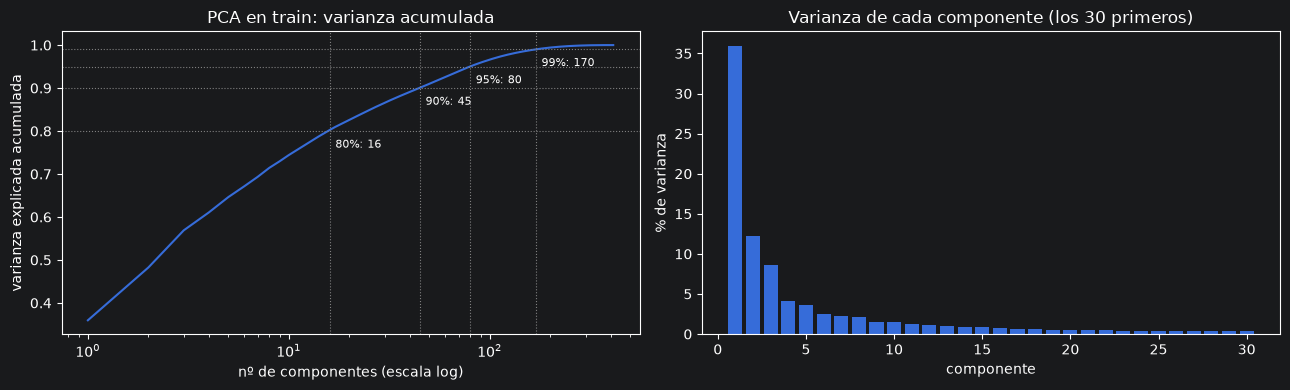

In [5]:
CLS_COLOR = {"bcc": "#ff7f0e", "mel": "#1f77b4", "scc": "#2ca02c"}
N_PLOT = 4             # nº de componentes de PCA en la matriz de scatter (2, 3, 4...)
N_LOAD = 3             # nº de componentes de los que se enseñan los loadings

viz_prep = Pipeline([("imp", SimpleImputer(strategy="median"))] + [
    ("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED)),
    ("std", StandardScaler())]).fit(Xtr)
Ztr, Zva = viz_prep.transform(Xtr), viz_prep.transform(Xva)

pca_viz = PCA(random_state=SEED).fit(Ztr)
evr = pca_viz.explained_variance_ratio_
cum = np.cumsum(evr)
n_for = {t: int(np.searchsorted(cum, t) + 1) for t in (0.80, 0.90, 0.95, 0.99)}
print("componentes necesarios para explicar:", {f"{int(t * 100)}%": n for t, n in n_for.items()}, f"(de {len(FEATS)})")
print("varianza explicada por los primeros:", {f"PC{i + 1}": f"{100 * v:.1f}%" for i, v in enumerate(evr[:6])})

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(np.arange(1, len(cum) + 1), cum)
for t, n in n_for.items():
    axs[0].axhline(t, ls=":", lw=0.8, color="gray")
    axs[0].axvline(n, ls=":", lw=0.8, color="gray")
    axs[0].annotate(f"{int(t * 100)}%: {n}", (n, t), textcoords="offset points", xytext=(4, -12), fontsize=8)
axs[0].set(xscale="log", xlabel="nº de componentes (escala log)", ylabel="varianza explicada acumulada",
           title="PCA en train: varianza acumulada")
axs[1].bar(np.arange(1, 31), 100 * evr[:30])
axs[1].set(xlabel="componente", ylabel="% de varianza", title="Varianza de cada componente (los 30 primeros)")
plt.tight_layout(); plt.show()

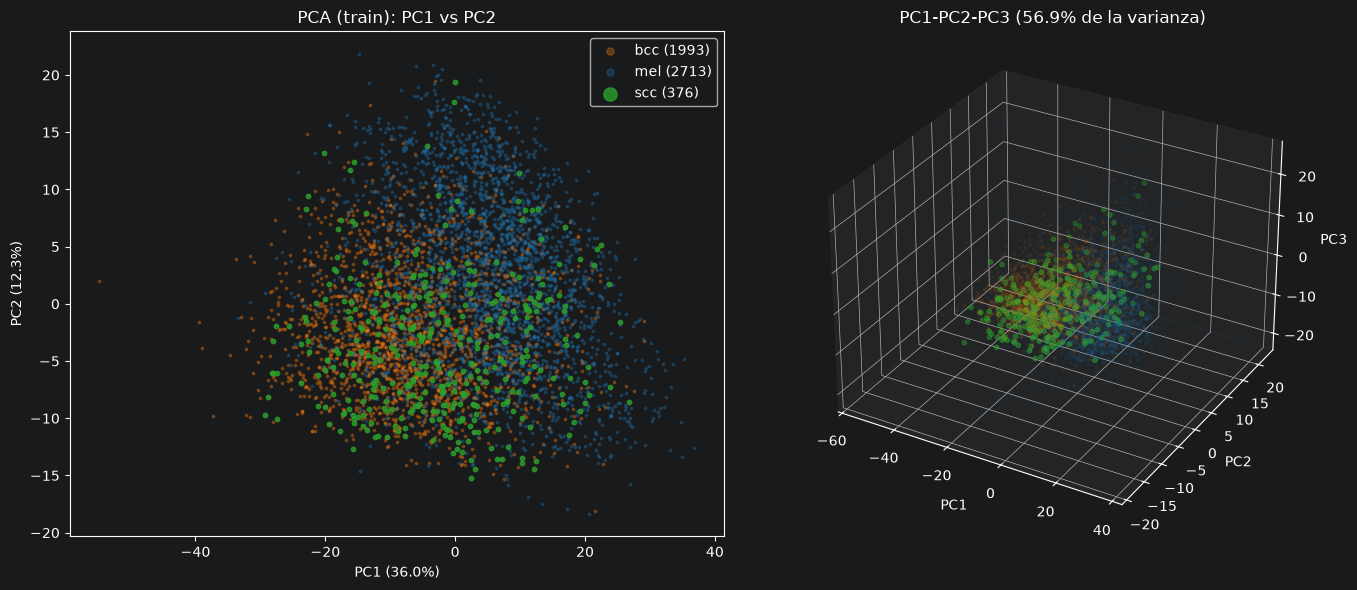

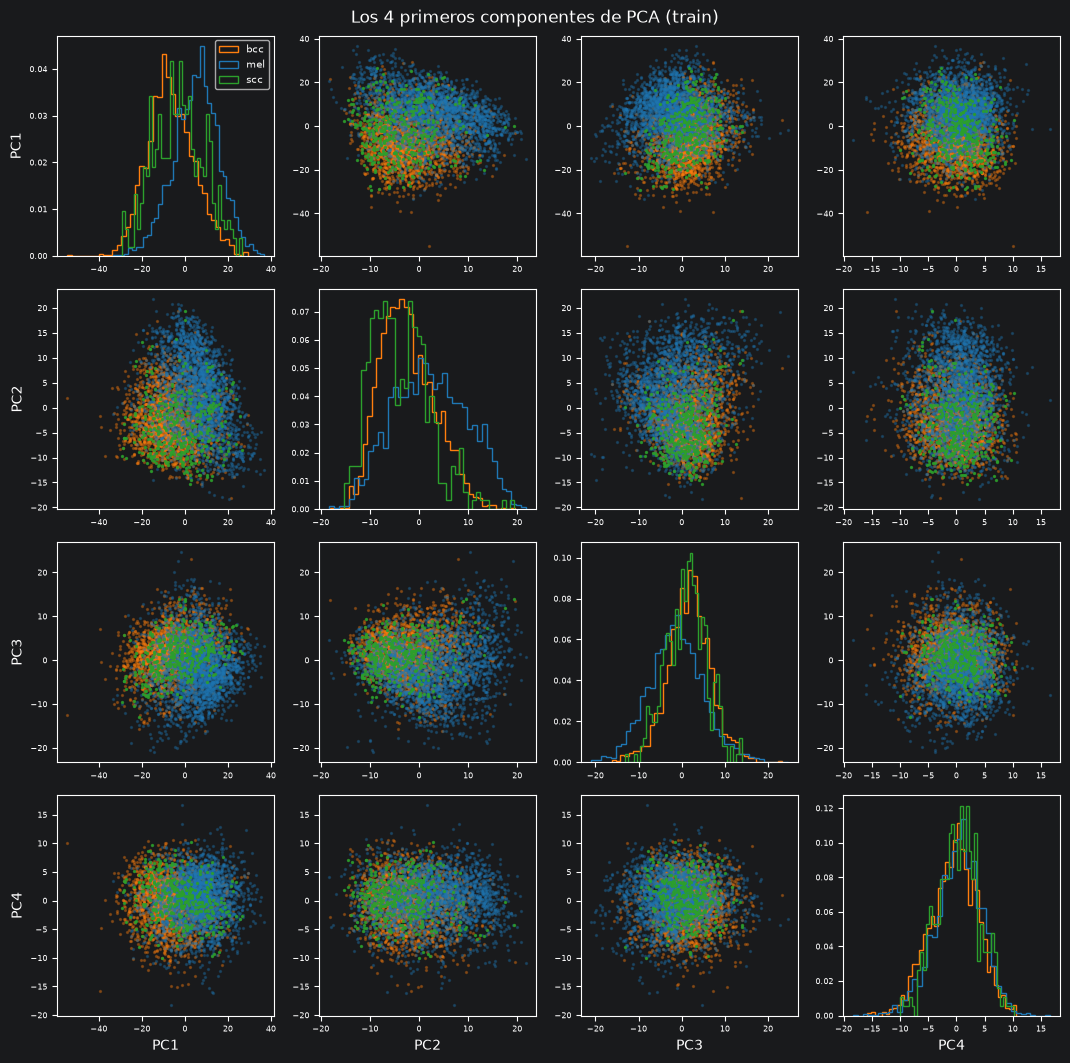

In [6]:
P = pca_viz.transform(Ztr)
style = lambda c: dict(s=10 if c == "scc" else 3, alpha=0.8 if c == "scc" else 0.3, color=CLS_COLOR[c])   # SCC encima

fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(1, 2, 1)
for j, c in enumerate(CLASSES):
    m = ytr == j
    ax.scatter(P[m, 0], P[m, 1], label=f"{c} ({m.sum()})", **style(c))
ax.set(xlabel=f"PC1 ({100 * evr[0]:.1f}%)", ylabel=f"PC2 ({100 * evr[1]:.1f}%)", title="PCA (train): PC1 vs PC2")
ax.legend(markerscale=3)
ax = fig.add_subplot(1, 2, 2, projection="3d")
for j, c in enumerate(CLASSES):
    m = ytr == j
    ax.scatter(P[m, 0], P[m, 1], P[m, 2], label=c, **style(c))
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title=f"PC1-PC2-PC3 ({100 * cum[2]:.1f}% de la varianza)")
plt.tight_layout(); plt.show()

# matriz de scatter de los N_PLOT primeros componentes (diagonal: distribución de cada clase en ese componente)
fig, axs = plt.subplots(N_PLOT, N_PLOT, figsize=(2.7 * N_PLOT, 2.7 * N_PLOT))
for i in range(N_PLOT):
    for j in range(N_PLOT):
        ax = axs[i, j]
        for k, c in enumerate(CLASSES):
            m = ytr == k
            if i == j:
                ax.hist(P[m, i], bins=40, density=True, histtype="step", color=CLS_COLOR[c], label=c)
            else:
                ax.scatter(P[m, j], P[m, i], **{**style(c), "s": 2})
        if i == N_PLOT - 1:
            ax.set_xlabel(f"PC{j + 1}")
        if j == 0:
            ax.set_ylabel(f"PC{i + 1}")
        ax.tick_params(labelsize=6)
axs[0, 0].legend(fontsize=7)
plt.suptitle(f"Los {N_PLOT} primeros componentes de PCA (train)"); plt.tight_layout(); plt.show()

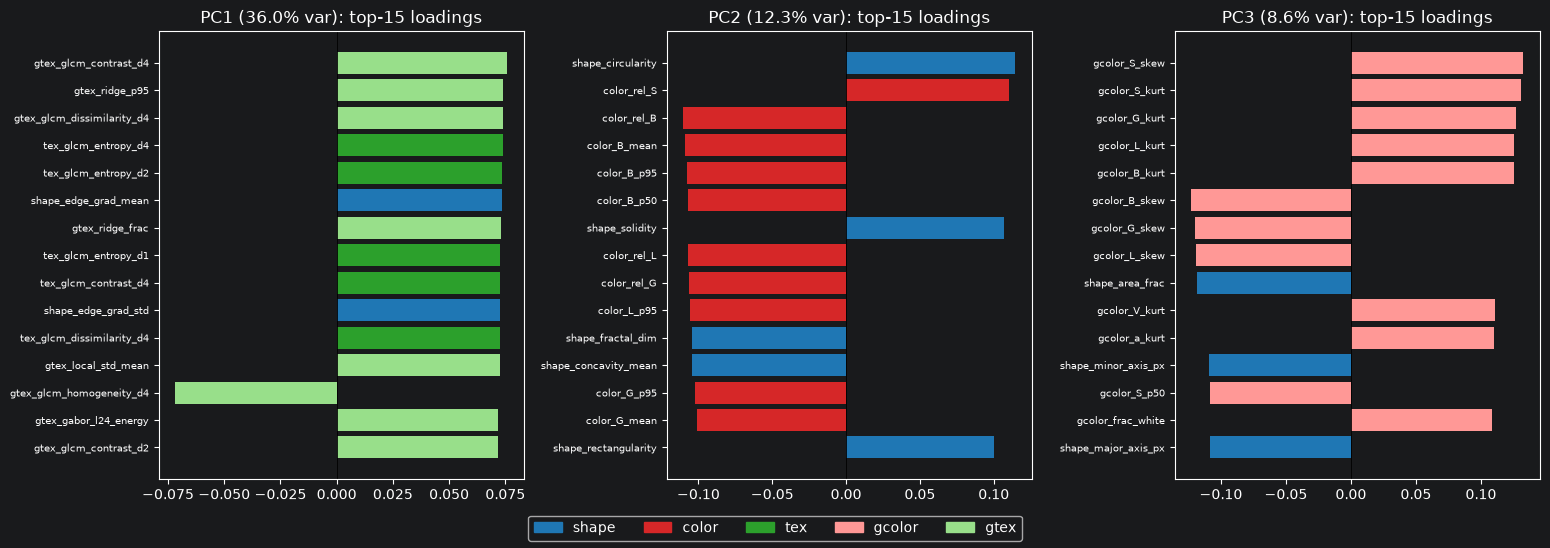

Peso de cada familia en los 10 primeros componentes:

         PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8   PC9  PC10  % de features
shape   0.03  0.25  0.06  0.18  0.02  0.15  0.37  0.09  0.20  0.02           0.13
color   0.10  0.42  0.03  0.05  0.33  0.48  0.35  0.28  0.20  0.66           0.20
tex     0.36  0.04  0.29  0.42  0.23  0.06  0.08  0.26  0.26  0.18           0.25
gcolor  0.11  0.13  0.51  0.04  0.18  0.25  0.12  0.13  0.06  0.05           0.17
gtex    0.40  0.16  0.11  0.31  0.23  0.05  0.08  0.25  0.28  0.09           0.25


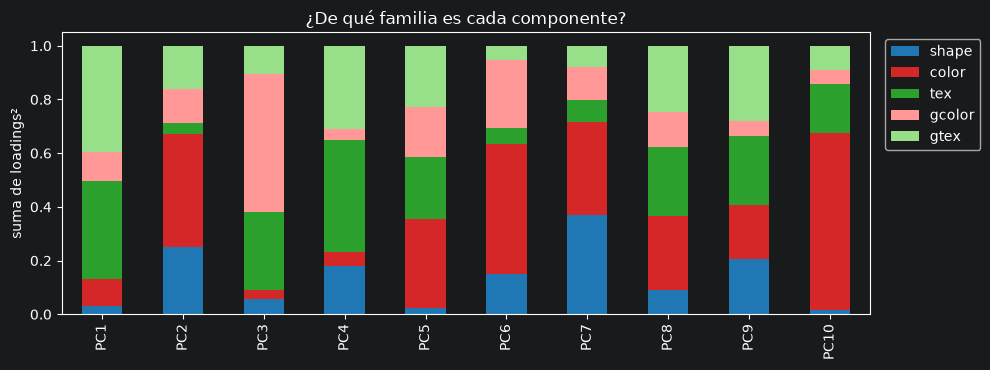

In [7]:
# Loadings: peso de cada feature original en cada componente (las features están estandarizadas, así que son comparables)
load = pd.DataFrame(pca_viz.components_[:max(N_LOAD, 10)].T, index=FEATS,
                    columns=[f"PC{i + 1}" for i in range(max(N_LOAD, 10))])

fig, axs = plt.subplots(1, N_LOAD, figsize=(5.2 * N_LOAD, 5.5))
for ax, pc in zip(np.atleast_1d(axs), load.columns[:N_LOAD]):
    top = load[pc].abs().sort_values(ascending=False).head(15).index[::-1]
    ax.barh(top, load.loc[top, pc], color=[FAM_COLOR[family(c)] for c in top])
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(f"{pc} ({100 * evr[int(pc[2:]) - 1]:.1f}% var): top-15 loadings")
    ax.tick_params(axis="y", labelsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM_COLOR.values()]
fig.legend(handles, FAM_COLOR.keys(), loc="lower center", ncol=len(FAM_COLOR))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

# Peso de cada familia en cada componente: suma de los loadings al cuadrado (cada componente suma 1).
# Compáralo con la proporción de features de cada familia: si una familia pesa mucho más que su proporción, ese
# componente es "sobre todo" esa familia.
fam_w = (load ** 2).groupby(lambda c: family(c)).sum().reindex(list(FAM_COLOR))
fam_w["% de features"] = pd.Series([family(c) for c in FEATS]).value_counts(normalize=True).reindex(list(FAM_COLOR))
print("Peso de cada familia en los 10 primeros componentes:\n")
print(fam_w.round(2).to_string())
ax = fam_w.drop(columns="% de features").T.plot(kind="bar", stacked=True, figsize=(10, 3.8),
                                                 color=[FAM_COLOR[f] for f in fam_w.index])
ax.set(ylabel="suma de loadings²", title="¿De qué familia es cada componente?")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

separación entre clases explicada por LD1, LD2: [0.011 0.011]


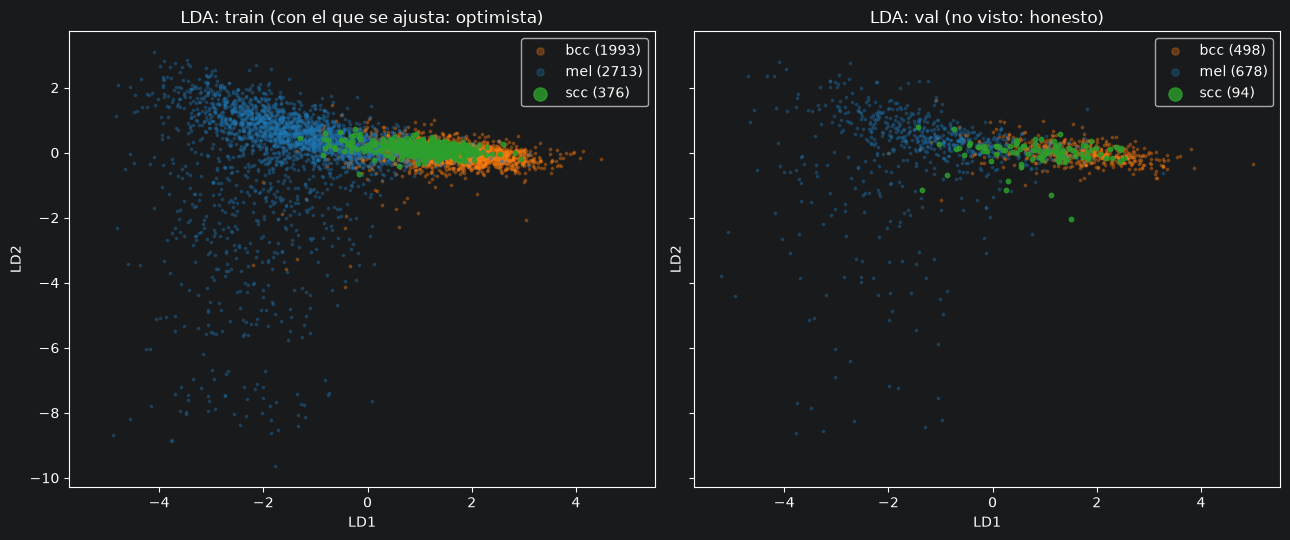

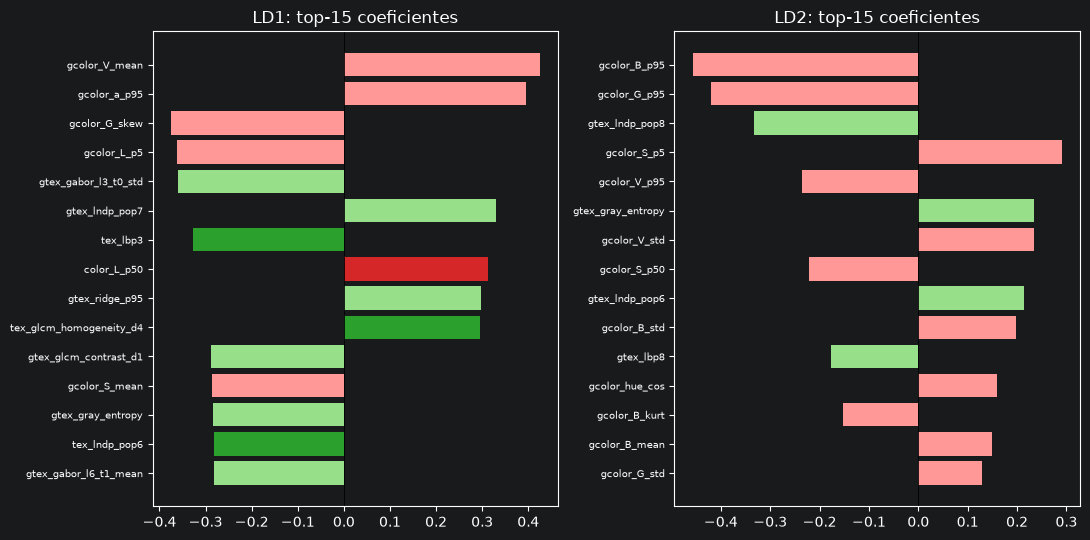

In [8]:
# LDA: 2 direcciones que mejor separan las 3 clases (priors iguales, igual que en el pipeline)
lda_viz = LinearDiscriminantAnalysis(n_components=2, solver="eigen", shrinkage="auto",
                                     priors=np.full(len(CLASSES), 1 / len(CLASSES))).fit(Ztr, ytr)
Ltr, Lva = lda_viz.transform(Ztr), lda_viz.transform(Zva)
print("separación entre clases explicada por LD1, LD2:", lda_viz.explained_variance_ratio_.round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, L, yy, title in [(axs[0], Ltr, ytr, "train (con el que se ajusta: optimista)"),
                         (axs[1], Lva, yva, "val (no visto: honesto)")]:
    for j, c in enumerate(CLASSES):
        m = yy == j
        ax.scatter(L[m, 0], L[m, 1], label=f"{c} ({m.sum()})", **style(c))
    ax.set(xlabel="LD1", ylabel="LD2", title=f"LDA: {title}")
    ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

# Coeficientes de cada discriminante sobre las features estandarizadas. Ojo: con features muy correlacionadas los
# coeficientes son inestables (se reparten el peso entre features parecidas); úsalo como orientación, no como verdad.
coef = pd.DataFrame(lda_viz.scalings_[:, :2], index=FEATS, columns=["LD1", "LD2"])
fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, ld in zip(axs, coef.columns):
    top = coef[ld].abs().sort_values(ascending=False).head(15).index[::-1]
    ax.barh(top, coef.loc[top, ld], color=[FAM_COLOR[family(c)] for c in top])
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(f"{ld}: top-15 coeficientes"); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

## 2. Modelos y validación cruzada (todas las reducciones)

- **todas / top-K:** imputación → [top-K] → cuantil (todos los modelos, `SCALE_ALL`) → SMOTE → modelo.
- **PCA / LDA:** imputación → cuantil → `StandardScaler` → PCA / LDA → SMOTE → modelo (no se vuelve a escalar).
- La parte de reducción (imputación + top-K / PCA / LDA) se ajusta **una vez por fold**, solo con el train del fold y
  **sin remuestrear**, y la comparten todos los modelos. Después todos los pares **modelo × fold** se entrenan a la vez.
- Las métricas de train (para ver el overfitting) se calculan sobre el train del fold **original**, sin remuestrear.
- `Dummy` es el suelo (kappa 0, balanced accuracy 0.33). Para el SVM, el AUC se calcula con un softmax de `decision_function`.

In [9]:
MAIN = "kappa"                     # métrica para ordenar y elegir el mejor modelo
SCORING = ["kappa", "bal_acc", "f1_macro", "auc_ovr", "ap_macro"] + [f"recall_{c}" for c in CLASSES]

# sin class_weight / sample_weight: el desbalance ya lo corrige el remuestreo
MODELS = {   # nombre: (estimador, ¿necesita escalado?, ¿usa sample_weight balanceado?)
    "Dummy": (DummyClassifier(strategy="prior"), False, False),
    "LogReg (baseline)": (LogisticRegression(C=0.5, max_iter=5000), True, False),
    "LDA": (LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto"), True, False),
    "KNN": (KNeighborsClassifier(n_neighbors=15, weights="distance"), True, False),
    "SVM-RBF": (SVC(C=1.0, gamma="scale"), True, False),
    "Decision Tree": (DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=SEED), False, False),
    "Random Forest": (RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=SEED, n_jobs=1), False, False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_depth=4,
                                                            early_stopping=False,
                                                            random_state=SEED), False, False),
}
if XGBClassifier is not None:
    MODELS["XGBoost"] = (XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=4, min_child_weight=3,
                                       subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0, tree_method="hist",
                                       objective="multi:softprob", eval_metric="mlogloss", n_jobs=1,
                                       random_state=SEED), False, False)

slug = lambda s: "".join(ch if ch.isalnum() else "_" for ch in s).strip("_").lower()


def make_selector(k, n_jobs=1):
    """Top-k features según la importancia de un Random Forest (con pesos balanceados).
    Igual que en los otros notebooks: se ajusta con el train del fold sin remuestrear."""
    est = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
                                 class_weight="balanced_subsample", random_state=SEED, n_jobs=n_jobs)
    return SelectFromModel(est, max_features=k, threshold=-np.inf)


def make_scaler():
    """Cuantil (-> normal) + StandardScaler, antes de PCA / LDA.
    El cuantil quita colas y outliers; el StandardScaler garantiza media 0 y desviación 1 exactas en todas las features
    (con features con muchos valores repetidos el cuantil solo no lo asegura). Sin esto, PCA se lo llevarían las
    features con más varianza por su escala, no por su información."""
    return [("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED)),
            ("std", StandardScaler())]


def make_reducer(red):
    kind, n = red
    if kind == "pca":
        return PCA(n_components=n, random_state=SEED)
    if kind == "lda":      # priors iguales: que la proyección no la dicte el desbalance (se ajusta antes del remuestreo)
        return LinearDiscriminantAnalysis(n_components=n, solver="eigen", shrinkage="auto",
                                          priors=np.full(len(CLASSES), 1 / len(CLASSES)))
    raise ValueError(f"reducción desconocida: {red}")


is_projected = lambda red: red is not None and red[0] in ("pca", "lda")


def make_prep(red, n_jobs=1):
    """Parte que se ajusta UNA vez por fold (solo con el train del fold, sin remuestrear) y comparten todos los modelos:
       None           -> imputación
       ("topk", K)    -> imputación -> top-K (Random Forest)
       ("pca"/"lda")  -> imputación -> cuantil -> StandardScaler -> PCA / LDA"""
    steps = [("imp", SimpleImputer(strategy="median"))]
    if red is not None and red[0] == "topk":
        steps.append(("sel", make_selector(red[1], n_jobs=n_jobs)))
    elif is_projected(red):
        steps += make_scaler() + [("red", make_reducer(red))]
    elif red is not None:
        raise ValueError(f"reducción desconocida: {red}")
    return Pipeline(steps)


def make_head(model, scale, projected=False):
    """[escalado] -> sampler -> modelo. ImbPipeline remuestrea solo en fit(); predict() no lo toca.
    Con PCA / LDA los datos ya llegan escalados y proyectados: no se vuelven a escalar."""
    steps = []
    if (scale or SCALE_ALL) and not projected:
        steps.append(("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED)))
    return ImbPipeline(steps + [("sampler", clone(SAMPLER)), ("clf", clone(model))])


def fit_head(model, scale, sw, X, y, projected=False):
    warnings.filterwarnings("ignore")
    kw = {"clf__sample_weight": compute_sample_weight("balanced", y)} if sw else {}
    return make_head(model, scale, projected).fit(X, y, **kw)


def predict_scores(est, X):
    """Probabilidades (n, 3). Si el modelo no tiene predict_proba (SVM), softmax de decision_function."""
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)
    d = est.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def mc_metrics(y, P, pred):
    rec = recall_score(y, pred, labels=list(range(len(CLASSES))), average=None, zero_division=0)
    out = {"kappa": cohen_kappa_score(y, pred), "bal_acc": balanced_accuracy_score(y, pred),
           "f1_macro": f1_score(y, pred, average="macro"),
           "auc_ovr": roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(len(CLASSES))))}
    Y = label_binarize(y, classes=list(range(len(CLASSES))))         # one-vs-rest
    ap = [average_precision_score(Y[:, j], P[:, j]) for j in range(len(CLASSES))]   # área bajo la curva PR
    out["ap_macro"] = float(np.mean(ap))
    out.update({f"recall_{c}": r for c, r in zip(CLASSES, rec)})
    out.update({f"ap_{c}": v for c, v in zip(CLASSES, ap)})
    return out


def _prep_fold(X, y, a, b, red, n_jobs=1):
    """Imputación (+ top-K, o escalado + PCA / LDA) ajustada solo con el train del fold."""
    warnings.filterwarnings("ignore")
    p = make_prep(red, n_jobs=n_jobs).fit(X[a], y[a])
    return p.transform(X[a]), p.transform(X[b])


def _eval_fold(model, scale, sw, X, y, a, b, prepped=None, projected=False):
    warnings.filterwarnings("ignore")
    if prepped is None:                       # sin reducción la imputación es instantánea: se hace aquí mismo
        prepped = _prep_fold(X, y, a, b, None)
    Xa, Xb = prepped
    m = fit_head(model, scale, sw, Xa, y[a], projected)
    test = mc_metrics(y[b], predict_scores(m, Xb), m.predict(Xb))      # fold de validación (no visto)
    train = mc_metrics(y[a], predict_scores(m, Xa), m.predict(Xa))     # mismo train del fold (overfitting)
    return test | {f"train_{key}": v for key, v in train.items()}


def run_cv_many(subsets, red, models=MODELS, return_raw=False):
    """CV de varios subconjuntos de features x varios modelos, todo en paralelo, con la reducción `red`
    (una de las de REDUCTIONS). subsets: {nombre: X}. Devuelve una tabla indexada por (subconjunto, modelo)."""
    y = ytr
    folds = list(skf.split(np.zeros(len(y)), y))
    Xs = {n: np.asarray(X, dtype=np.float64) for n, X in subsets.items()}
    prepped = {}
    if red is not None:                                    # 1) reducción una vez por (subconjunto, fold)
        keys = [(n, f) for n in Xs for f in range(len(folds))]
        inner = max(1, N_JOBS // len(keys))                # cores sobrantes -> árboles del RF selector (top-K)
        out = Parallel(n_jobs=min(N_JOBS, len(keys)))(
            delayed(_prep_fold)(Xs[n], y, *folds[f], red, inner) for n, f in keys)
        prepped = dict(zip(keys, out))
    jobs = [(n, m, f) for n in Xs for m in models for f in range(len(folds))]   # 2) todos los modelo x fold a la vez
    res = Parallel(n_jobs=N_JOBS)(
        delayed(_eval_fold)(*models[m], Xs[n] if red is None else None, y, *folds[f], prepped.get((n, f)),
                            is_projected(red))
        for n, m, f in jobs)
    df = pd.DataFrame(res).assign(subset=[j[0] for j in jobs], model=[j[1] for j in jobs])
    g = df.groupby(["subset", "model"], sort=False)[SCORING]
    mean, std = g.mean(), g.std(ddof=0)
    table = pd.DataFrame({m: mean[m].map("{:.3f}".format) + " ± " + std[m].map("{:.3f}".format) for m in SCORING})
    table["_main"] = mean[MAIN]
    return (table, df) if return_raw else table


def run_cv(X, red, models=MODELS, return_raw=False):
    table, raw = run_cv_many({"X": X}, red, models, return_raw=True)
    table = table.droplevel("subset").sort_values("_main", ascending=False)
    return (table, raw) if return_raw else table

### 2b. Ajuste de hiperparámetros (grid search por kappa)
Para cada modelo se prueban todas las combinaciones de su rejilla con la **misma CV estratificada de 5 folds** y el
**mismo pipeline** que en el resto del notebook (imputación → escalado → remuestreo / pesos → modelo), así que el
remuestreo se hace dentro de cada fold también aquí. Gana la combinación con mejor **kappa medio** y sustituye a los
parámetros de `MODELS`: la CV de abajo, la evaluación en val, los ensembles y los modelos guardados usan ya los
parámetros ajustados.

- Rejillas pequeñas y con sentido (~60 combinaciones en total): árboles poco o medio profundos, 200-600 iteraciones de
  boosting, learning rate 0.05-0.1, regularización de LogReg y SVM, nº de vecinos de KNN.
- En Random Forest no se ajusta el nº de árboles (más árboles nunca empeora, solo tarda más): se fija en 400 y se ajustan
  profundidad, tamaño mínimo de hoja y nº de features por división.
- Se ajusta con todas las features (`TUNE_ON = None`); en la variante top-K / PCA se reutilizan los mismos parámetros.
- El kappa de CV del modelo ajustado es un poco **optimista** (es el máximo de muchas combinaciones evaluadas en los mismos
  folds). La estimación honesta es **val**.
- `TUNE = True` hace la búsqueda y la guarda en `OUT_DIR/best_params.json`; con `TUNE = False` se cargan los parámetros de
  ese archivo (si existe) sin repetir la búsqueda.

In [10]:
import json
from itertools import product

TUNE = True            # True: grid search y guarda OUT_DIR/best_params.json | False: carga ese json (si no existe, parámetros por defecto)
TUNE_ON = None         # features con las que se ajusta (None = todas)

PARAM_GRIDS = {        # modelo: {parámetro: valores}. Combinaciones = producto de los tamaños
    "LogReg (baseline)": {"C": [0.01, 0.05, 0.2, 1.0, 5.0]},                                      # 5
    "KNN": {"n_neighbors": [5, 15, 31, 51], "weights": ["uniform", "distance"]},                  # 8
    "SVM-RBF": {"C": [0.3, 1.0, 3.0, 10.0]},                                                      # 4
    "Decision Tree": {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [5, 20]},                   # 8
    "Random Forest": {"max_depth": [None, 15], "min_samples_leaf": [1, 3, 8],
                      "max_features": ["sqrt", 0.1]},                                              # 12
    "HistGradientBoosting": {"max_depth": [3, 5, 8], "learning_rate": [0.05, 0.1],
                             "max_iter": [200, 500]},                                              # 12
    "XGBoost": {"max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1], "n_estimators": [300, 600]},  # 12
}

params_path = OUT_DIR / "best_params.json"
label = lambda p: ", ".join(f"{k}={v}" for k, v in p.items())

if TUNE:
    candidates, owner = {}, {}
    for m, grid in PARAM_GRIDS.items():
        if m not in MODELS:
            continue
        est, scale, sw = MODELS[m]
        for vals in product(*grid.values()):
            p = dict(zip(grid, vals))
            name = f"{m} | {label(p)}"
            candidates[name] = (clone(est).set_params(**p), scale, sw)
            owner[name] = (m, p)
    print(f"Grid search: {len(candidates)} combinaciones x {CV_FOLDS} folds = {len(candidates) * CV_FOLDS} entrenamientos "
          f"(elige por {MAIN}, N_JOBS = {N_JOBS})\n")
    t_grid = run_cv(Xtr, TUNE_ON, models=candidates)          # ordenada de mejor a peor por MAIN
    grid_res = pd.DataFrame({"modelo": [owner[n][0] for n in t_grid.index],
                             "parámetros": [label(owner[n][1]) for n in t_grid.index],
                             MAIN: t_grid["_main"].round(4).to_numpy(),
                             f"{MAIN} (media ± std)": t_grid[MAIN].to_numpy(),
                             "bal_acc": t_grid["bal_acc"].to_numpy(),
                             "recall_scc": t_grid["recall_scc"].to_numpy()}, index=t_grid.index)
    grid_res.to_csv(OUT_DIR / "grid_search.csv", index=False)
    best_params = {}
    for m in PARAM_GRIDS:
        sub = grid_res[grid_res["modelo"] == m]
        if len(sub) == 0:
            continue
        best_params[m] = owner[sub.index[0]][1]
        print(f"--- {m}: las 3 mejores de {len(sub)} ---")
        print(sub.drop(columns="modelo").head(3).to_string(index=False), "\n")
    params_path.write_text(json.dumps(best_params, indent=2), encoding="utf-8")
else:
    best_params = json.loads(params_path.read_text(encoding="utf-8")) if params_path.exists() else {}
    print(f"Parámetros cargados de {params_path}" if best_params else "No hay best_params.json: parámetros por defecto")

for m, p in best_params.items():                              # los mejores parámetros sustituyen a los de MODELS
    if m in MODELS:
        est, scale, sw = MODELS[m]
        MODELS[m] = (clone(est).set_params(**p), scale, sw)
print("Parámetros usados a partir de aquí:")
for m, p in best_params.items():
    print(f"  {m:<22s} {label(p)}")

Grid search: 61 combinaciones x 5 folds = 305 entrenamientos (elige por kappa, N_JOBS = 26)

--- LogReg (baseline): las 3 mejores de 5 ---
parámetros  kappa kappa (media ± std)       bal_acc    recall_scc
     C=0.2 0.6210       0.621 ± 0.018 0.698 ± 0.026 0.505 ± 0.075
     C=1.0 0.6187       0.619 ± 0.019 0.691 ± 0.027 0.484 ± 0.073
    C=0.05 0.6178       0.618 ± 0.016 0.704 ± 0.026 0.534 ± 0.072 

--- KNN: las 3 mejores de 8 ---
                      parámetros  kappa kappa (media ± std)       bal_acc    recall_scc
 n_neighbors=5, weights=distance 0.5160       0.516 ± 0.018 0.705 ± 0.013 0.742 ± 0.057
  n_neighbors=5, weights=uniform 0.5055       0.505 ± 0.017 0.698 ± 0.013 0.734 ± 0.056
n_neighbors=15, weights=distance 0.4430       0.443 ± 0.014 0.670 ± 0.012 0.787 ± 0.048 

--- SVM-RBF: las 3 mejores de 4 ---
parámetros  kappa kappa (media ± std)       bal_acc    recall_scc
    C=10.0 0.7552       0.755 ± 0.027 0.730 ± 0.035 0.386 ± 0.092
     C=3.0 0.7329       0.733 ± 0.030 0.7

### CV con los modelos ajustados

In [11]:
print(f"CV {CV_FOLDS} folds en train ({len(Xtr)} imágenes), {len(MODELS)} modelos x {len(REDUCTIONS)} reducciones, "
      f"remuestreo {RESAMPLING}, N_JOBS = {N_JOBS}\n")
cv_tables, cv_raw = {}, {}
for rname, red in REDUCTIONS.items():
    t, raw = run_cv(Xtr, red, return_raw=True)
    cv_tables[rname], cv_raw[rname] = t, raw
    t.drop(columns="_main").to_csv(OUT_DIR / f"cv_{slug(rname)}.csv")
    print(f"--- {rname}  {red if red is not None else f'(las {len(FEATS)} features)'} ---")
    print(t.drop(columns="_main").to_string(), "\n")

CV 5 folds en train (5082 imágenes), 9 modelos x 9 reducciones, remuestreo SMOTE, N_JOBS = 26

--- todas  (las 412 features) ---
                              kappa        bal_acc       f1_macro        auc_ovr       ap_macro     recall_bcc     recall_mel     recall_scc
model                                                                                                                                       
SVM-RBF               0.755 ± 0.027  0.730 ± 0.035  0.747 ± 0.034  0.916 ± 0.015  0.773 ± 0.031  0.882 ± 0.018  0.921 ± 0.007  0.386 ± 0.092
HistGradientBoosting  0.746 ± 0.031  0.708 ± 0.029  0.726 ± 0.030  0.937 ± 0.010  0.798 ± 0.023  0.892 ± 0.022  0.915 ± 0.010  0.317 ± 0.072
XGBoost               0.744 ± 0.028  0.713 ± 0.029  0.734 ± 0.028  0.936 ± 0.009  0.794 ± 0.019  0.884 ± 0.020  0.916 ± 0.009  0.341 ± 0.079
Random Forest         0.694 ± 0.030  0.702 ± 0.027  0.715 ± 0.028  0.922 ± 0.008  0.770 ± 0.020  0.861 ± 0.023  0.875 ± 0.012  0.370 ± 0.065
LDA                   0.6

### Resumen: modelo × reducción
Media de los 5 folds de cada modelo con cada reducción. Lo normal es que PCA ayude (o no perjudique) a los modelos
lineales y de distancias (LogReg, LDA, SVM, KNN) y perjudique a los árboles. Mira el kappa **y** el recall de SCC.

--- CV kappa (media de 5 folds) ---
                      todas  top-30  top-50  top-100  PCA 95%  PCA-10  PCA-30  PCA-60  LDA-2
model                                                                                       
Dummy                 0.000   0.000   0.000    0.000    0.000   0.000   0.000   0.000  0.000
LogReg (baseline)     0.621   0.508   0.532    0.568    0.595   0.475   0.570   0.587  0.554
LDA                   0.623   0.499   0.524    0.564    0.566   0.468   0.553   0.566  0.533
KNN                   0.516   0.501   0.535    0.583    0.546   0.548   0.583   0.561  0.515
SVM-RBF               0.755   0.571   0.628    0.731    0.744   0.600   0.715   0.742  0.523
Decision Tree         0.511   0.468   0.466    0.498    0.417   0.424   0.445   0.443  0.528
Random Forest         0.694   0.625   0.655    0.692    0.672   0.653   0.690   0.670  0.544
HistGradientBoosting  0.746   0.642   0.671    0.734    0.719   0.642   0.720   0.712  0.513
XGBoost               0.744   0.63

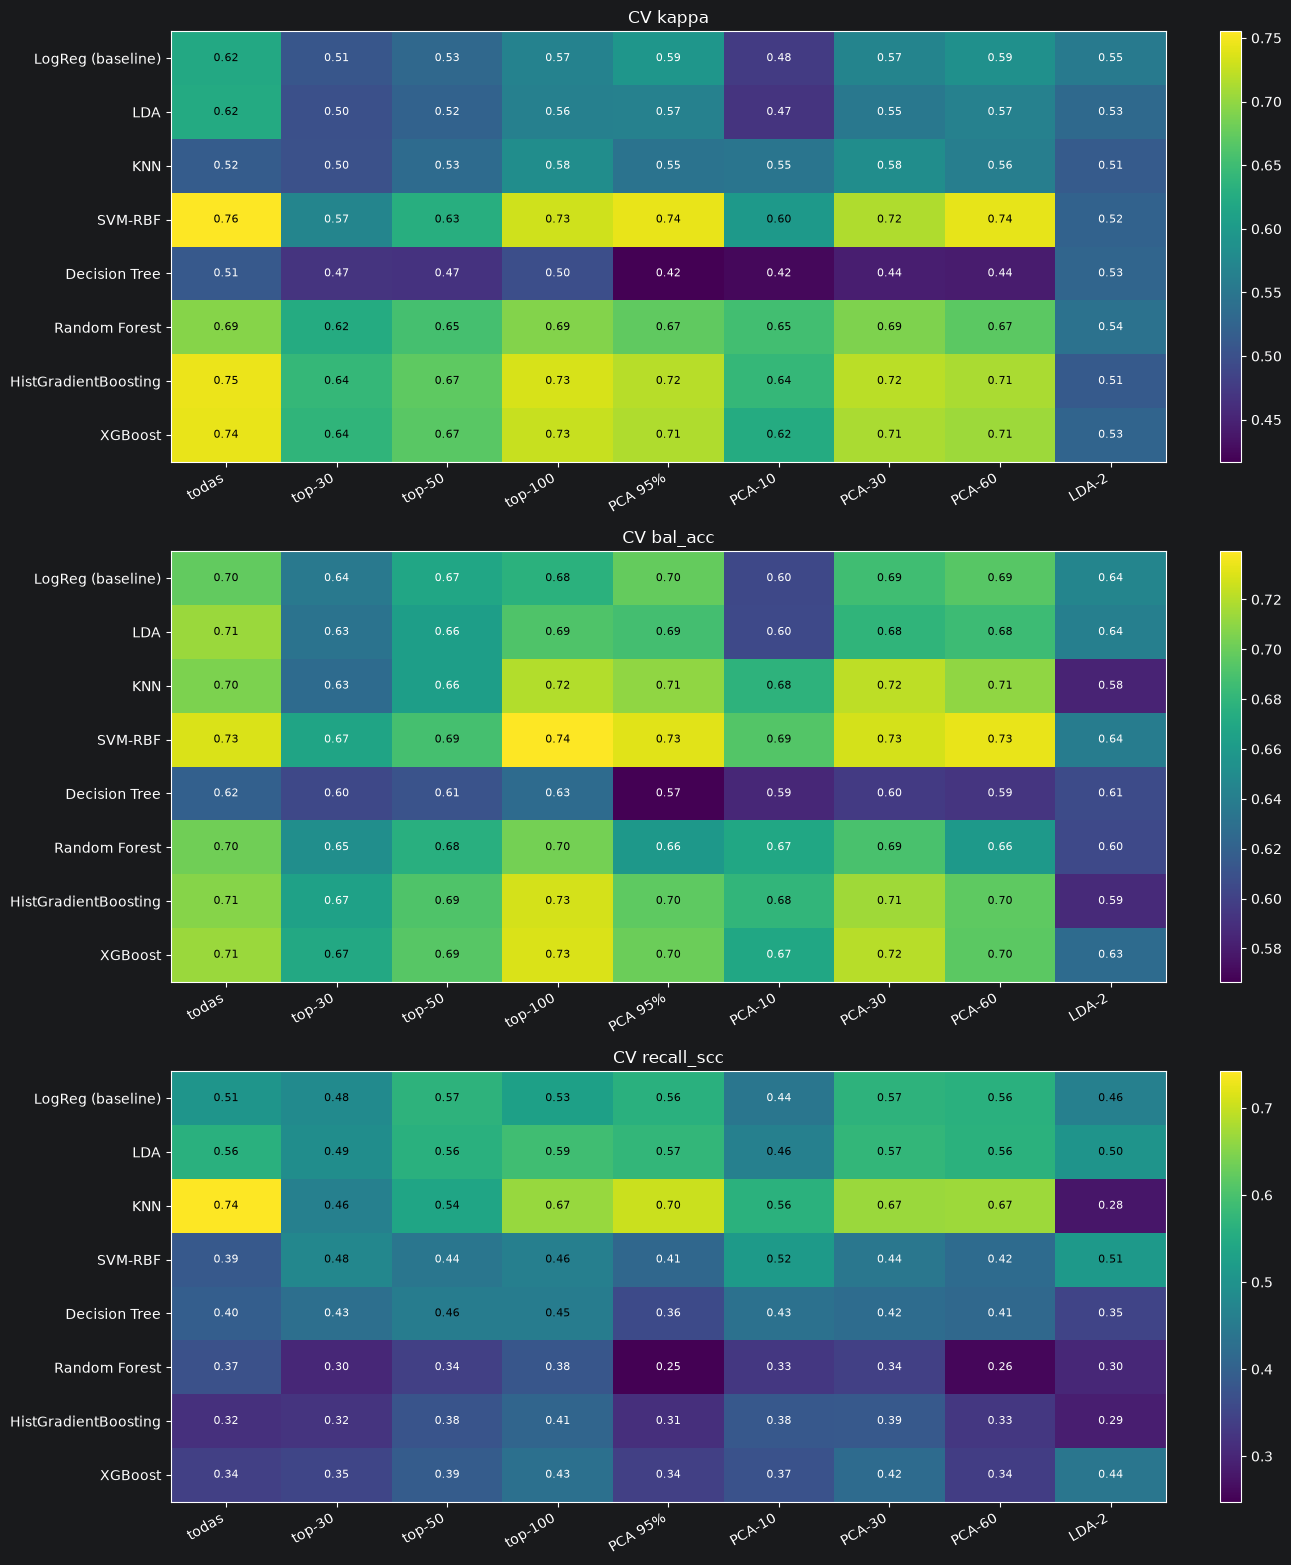

Mejor combinación en CV (kappa): todas + SVM-RBF = 0.755


In [12]:
mean_of = lambda metric: pd.DataFrame({r: raw.groupby("model", sort=False)[metric].mean()
                                       for r, raw in cv_raw.items()}).reindex(list(MODELS))
summ = {m: mean_of(m) for m in ["kappa", "bal_acc", "recall_scc"]}
for m, t in summ.items():
    print(f"--- CV {m} (media de {CV_FOLDS} folds) ---")
    print(t.round(3).to_string(), "\n")
    t.round(4).to_csv(OUT_DIR / f"summary_cv_{m}.csv")

fig, axs = plt.subplots(len(summ), 1, figsize=(1.0 * len(REDUCTIONS) + 4, len(summ) * (0.45 * len(MODELS) + 1.2)))
for ax, (m, t) in zip(np.atleast_1d(axs), summ.items()):
    t = t.drop(index="Dummy", errors="ignore")
    v = t.to_numpy(dtype=float)
    im = ax.imshow(v, cmap="viridis", aspect="auto")
    ax.set_xticks(range(t.shape[1]), t.columns, rotation=30, ha="right")
    ax.set_yticks(range(t.shape[0]), t.index)
    for (i, j), x in np.ndenumerate(v):
        ax.text(j, i, f"{x:.2f}", ha="center", va="center", fontsize=8, color="w" if x < np.nanmean(v) else "k")
    ax.set_title(f"CV {m}")
    fig.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout(); plt.show()

best_red = max(cv_tables, key=lambda r: cv_tables[r]["_main"].iloc[0])     # variante cuyo mejor modelo tiene más MAIN
print(f"Mejor combinación en CV ({MAIN}): {best_red} + {cv_tables[best_red].index[0]} "
      f"= {cv_tables[best_red]['_main'].iloc[0]:.3f}")

### ¿Hay overfitting? Train vs CV
Para `todas` y para la mejor reducción de la CV. Rendimiento sobre el mismo train con el que se entrena cada fold frente
al fold de validación (sale de la CV de arriba, no se entrena nada nuevo). En Random Forest y XGBoost es normal que train
esté cerca de 1.0; en KNN con `weights="distance"` train es siempre 1.0 (cada imagen es su propio vecino). Lo que manda es la CV.

In [13]:
def train_vs_cv(raw):
    g = raw.groupby("model", sort=False)
    t = pd.DataFrame({"train_kappa": g["train_kappa"].mean(), "cv_kappa": g["kappa"].mean(),
                      "train_bal_acc": g["train_bal_acc"].mean(), "cv_bal_acc": g["bal_acc"].mean(),
                      "train_recall_scc": g["train_recall_scc"].mean(), "cv_recall_scc": g["recall_scc"].mean()})
    t.insert(2, "gap_kappa", t["train_kappa"] - t["cv_kappa"])
    t.insert(5, "gap_bal_acc", t["train_bal_acc"] - t["cv_bal_acc"])
    return t.sort_values("cv_kappa", ascending=False).round(3)


for r in dict.fromkeys(x for x in ("todas", best_red) if x in cv_raw):
    ovf = train_vs_cv(cv_raw[r])
    print(f"--- {r}: train vs CV ---")
    print(ovf.to_string(), "\n")
    ovf.to_csv(OUT_DIR / f"train_vs_cv_{slug(r)}.csv")

--- todas: train vs CV ---
                      train_kappa  cv_kappa  gap_kappa  train_bal_acc  cv_bal_acc  gap_bal_acc  train_recall_scc  cv_recall_scc
model                                                                                                                          
SVM-RBF                     0.997     0.755      0.242          0.999       0.730        0.269             1.000          0.386
HistGradientBoosting        1.000     0.746      0.254          1.000       0.708        0.292             1.000          0.317
XGBoost                     1.000     0.744      0.256          1.000       0.713        0.287             1.000          0.341
Random Forest               1.000     0.694      0.306          1.000       0.702        0.298             1.000          0.370
LDA                         0.712     0.623      0.089          0.823       0.713        0.110             0.811          0.561
LogReg (baseline)           0.750     0.621      0.129          0.841       0

## 3. Ablación por familias
El mejor modelo de la CV (por kappa) con cada familia sola y combinadas (todas en paralelo). Ojo con las de **imagen entera** (`gcolor`, `gtex`):
pueden captar la cámara o el fondo en vez de la lesión.

In [14]:
ABL_MODEL = cv_tables.get("todas", cv_tables[best_red]).index[0]   # el mejor de la CV con todas las features
fam_cols = {f: [c for c in FEATS if family(c) == f] for f in ["shape", "color", "tex", "gcolor", "gtex"]}
lesion = fam_cols["shape"] + fam_cols["color"] + fam_cols["tex"]
imagen = fam_cols["gcolor"] + fam_cols["gtex"]
subsets = {"solo forma": fam_cols["shape"], "solo color": fam_cols["color"], "solo textura": fam_cols["tex"],
           "solo gcolor": fam_cols["gcolor"], "solo gtex": fam_cols["gtex"],
           "forma + color": fam_cols["shape"] + fam_cols["color"], "color + textura": fam_cols["color"] + fam_cols["tex"],
           "lesión (shape+color+tex)": lesion, "imagen entera (gcolor+gtex)": imagen, "todas": FEATS}
abl = run_cv_many({name: Xtr[cols] for name, cols in subsets.items()}, red=None,
                  models={ABL_MODEL: MODELS[ABL_MODEL]}).droplevel("model")
abl.insert(0, "n_features", [len(c) for c in subsets.values()])
print(f"Ablación con {ABL_MODEL}\n")
print(abl.drop(columns="_main").to_string())
abl.drop(columns="_main").to_csv(OUT_DIR / "ablation_families.csv")

Ablación con SVM-RBF

                             n_features          kappa        bal_acc       f1_macro        auc_ovr       ap_macro     recall_bcc     recall_mel     recall_scc
subset                                                                                                                                                         
solo forma                           52  0.485 ± 0.025  0.558 ± 0.020  0.559 ± 0.022  0.765 ± 0.008  0.582 ± 0.016  0.741 ± 0.026  0.776 ± 0.013  0.157 ± 0.044
solo color                           82  0.618 ± 0.009  0.669 ± 0.011  0.658 ± 0.009  0.866 ± 0.011  0.683 ± 0.017  0.781 ± 0.005  0.842 ± 0.014  0.383 ± 0.034
solo textura                        104  0.581 ± 0.032  0.658 ± 0.020  0.649 ± 0.020  0.841 ± 0.020  0.663 ± 0.017  0.744 ± 0.030  0.828 ± 0.009  0.402 ± 0.027
solo gcolor                          70  0.597 ± 0.028  0.669 ± 0.038  0.651 ± 0.029  0.856 ± 0.018  0.654 ± 0.020  0.763 ± 0.013  0.823 ± 0.018  0.420 ± 0.110
solo gtex         

## 4. Evaluación final en val
Se usa la reducción (todas, top-K, PCA o LDA) cuyo mejor modelo haya dado mejor kappa en la CV, **sin mirar val**
(se puede fijar a mano con `FINAL_RED_NAME`, pero decidiéndolo con la CV). Cada modelo se entrena con **todo train**
(en paralelo) y se evalúa una sola vez en val. El IC95 % del kappa sale de un bootstrap sobre val.
El sampler solo sirve para entrenar, así que el pipeline final se guarda **sin** él
(imputación → [top-K | cuantil → StandardScaler → PCA/LDA] → [escalado] → modelo). Predice exactamente igual.

In [15]:
FINAL_RED_NAME = best_red          # elegida por la CV; se puede fijar a mano (p. ej. "PCA-30"), pero con la CV, no con val
FINAL_RED = REDUCTIONS[FINAL_RED_NAME]
res_cv = cv_tables[FINAL_RED_NAME]
best = res_cv.index[0]                                  # mejor modelo según la CV (no según val)
print(f"Reducción para el modelo final: {FINAL_RED_NAME} {FINAL_RED if FINAL_RED is not None else ''} | mejor en CV: {best}\n")


def boot_ci(y, pred, fn=cohen_kappa_score, n=1000, seed=0):
    rng = np.random.RandomState(seed)
    vals = [fn(y[i], pred[i]) for i in (rng.choice(len(y), len(y), replace=True) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])


proj = is_projected(FINAL_RED)
prep = make_prep(FINAL_RED, n_jobs=N_JOBS).fit(Xtr, ytr)          # imputación (+ reducción) una sola vez
Xtr_s, Xva_s = prep.transform(Xtr), prep.transform(Xva)
print(f"dimensiones que ve el modelo: {Xtr_s.shape[1]}\n")
heads = Parallel(n_jobs=N_JOBS)(delayed(fit_head)(est, scale, sw, Xtr_s, ytr, proj) for est, scale, sw in MODELS.values())

fitted, rows, probas, preds = {}, [], {}, {}
for name, head in zip(MODELS, heads):
    pipe = Pipeline(prep.steps + [s for s in head.steps if s[0] != "sampler"])   # ya entrenado, sin el sampler (acepta las features crudas)
    P, pred = predict_scores(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, pred)
    fitted[name], probas[name], preds[name] = pipe, P, pred
    rows.append({"modelo": name, **mc_metrics(yva, P, pred), "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]"})
val_res = pd.DataFrame(rows).set_index("modelo").sort_values("kappa", ascending=False)
print(f"Val ({len(Xva)} imágenes):\n")
print(val_res.round(3).to_string())
val_res.round(4).to_csv(OUT_DIR / "val_results.csv")

Reducción para el modelo final: todas  | mejor en CV: SVM-RBF

dimensiones que ve el modelo: 412

Val (1270 imágenes):

                      kappa  bal_acc  f1_macro  auc_ovr  ap_macro  recall_bcc  recall_mel  recall_scc  ap_bcc  ap_mel  ap_scc     kappa IC95%
modelo                                                                                                                                       
HistGradientBoosting  0.778    0.749     0.777    0.954     0.853       0.918       0.914       0.415   0.947   0.975   0.638  [0.747, 0.807]
SVM-RBF               0.776    0.776     0.793    0.934     0.819       0.900       0.909       0.521   0.926   0.972   0.560  [0.743, 0.808]
XGBoost               0.760    0.730     0.756    0.949     0.839       0.912       0.907       0.372   0.942   0.972   0.602  [0.727, 0.793]
Random Forest         0.698    0.730     0.739    0.924     0.793       0.861       0.861       0.468   0.913   0.954   0.512  [0.662, 0.735]
LogReg (baseline)     0.626 

### Informativo: el mejor modelo de cada reducción, en val
Para cada variante de `REDUCTIONS`, su mejor modelo de la CV entrenado con todo train y evaluado en val. Sirve para ver si
val **confirma** la CV, **no para elegir**: si eliges mirando esta tabla, val deja de ser una estimación honesta.
Con 1270 imágenes (94 SCC), diferencias dentro del IC95 % son ruido. Si val contradice a la CV claramente (fuera del IC),
es una pista de que algo pasa (por ejemplo, que train y val no se parecen).

In [16]:
VAL_ALL_REDUCTIONS = True        # False para saltarlo (entrena un modelo más por reducción)


def _best_of_reduction(rname):
    warnings.filterwarnings("ignore")
    red, m = REDUCTIONS[rname], cv_tables[rname].index[0]
    p = make_prep(red).fit(Xtr, ytr)
    h = fit_head(*MODELS[m], p.transform(Xtr), ytr, is_projected(red))
    Xv = p.transform(Xva)
    return m, predict_scores(h, Xv), h.predict(Xv)


if VAL_ALL_REDUCTIONS:
    out = Parallel(n_jobs=min(N_JOBS, len(REDUCTIONS)))(delayed(_best_of_reduction)(r) for r in REDUCTIONS)
    rows = []
    for rname, (m, P, pred) in zip(REDUCTIONS, out):
        lo, hi = boot_ci(yva, pred)
        rows.append({"reducción": rname, "mejor modelo (CV)": m, "cv_kappa": cv_tables[rname]["_main"].iloc[0],
                     **mc_metrics(yva, P, pred), "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]"})
    val_by_red = pd.DataFrame(rows).set_index("reducción")
    cols = ["mejor modelo (CV)", "cv_kappa", "kappa", "kappa IC95%", "bal_acc", "f1_macro", "auc_ovr", "ap_macro"] + \
           [f"recall_{c}" for c in CLASSES]
    print(val_by_red[cols].round(3).to_string())
    val_by_red.round(4).to_csv(OUT_DIR / "val_best_per_reduction.csv")

              mejor modelo (CV)  cv_kappa  kappa     kappa IC95%  bal_acc  f1_macro  auc_ovr  ap_macro  recall_bcc  recall_mel  recall_scc
reducción                                                                                                                                 
todas                   SVM-RBF     0.755  0.776  [0.743, 0.808]    0.776     0.793    0.934     0.819       0.900       0.909       0.521
top-30     HistGradientBoosting     0.642  0.664  [0.629, 0.699]    0.692     0.691    0.904     0.732       0.841       0.851       0.383
top-50     HistGradientBoosting     0.671  0.686  [0.650, 0.718]    0.701     0.703    0.922     0.753       0.855       0.864       0.383
top-100    HistGradientBoosting     0.734  0.751  [0.720, 0.785]    0.762     0.762    0.946     0.803       0.882       0.895       0.511
PCA 95%                 SVM-RBF     0.744  0.754  [0.722, 0.786]    0.758     0.764    0.930     0.806       0.886       0.900       0.489
PCA-10            Random Fo

### 4b. Ensembles (soft voting) de los mejores modelos
Cada miembro da sus probabilidades para BCC / MEL / SCC, se promedian (con pesos si se indican) y gana la clase con la
media más alta. Un ensemble mejora cuando sus miembros se equivocan en imágenes **distintas**: XGBoost y HGB son muy
parecidos (fallan en lo mismo), mientras que SVM y LogReg aportan más diversidad y recuperan más SCC.

- Variantes (`ENSEMBLES`): XGB+HGB+SVM, HGB+SVM, HGB+SVM con el SVM pesando el doble, y HGB+SVM+LogReg. Los miembros
  usan los **parámetros ajustados** en 2b.
- Mismo pipeline que el resto (el remuestreo se hace una vez y todos los miembros entrenan con los mismos datos).
- El SVM de los ensembles usa `probability=True` (calibración de Platt con una CV interna: ~5× más lento que el SVM normal).
- Se evalúan **por CV** (`ENS_CV = True`) igual que los demás y se añaden a la tabla de val y a las matrices de confusión.
  `best` pasa a ser el mejor de la CV contando también los ensembles (nunca se elige mirando val).

In [17]:
from sklearn.ensemble import VotingClassifier

ENSEMBLES = {          # nombre: (miembros, pesos o None = media simple)
    "Ens XGB+HGB+SVM": (["XGBoost", "HistGradientBoosting", "SVM-RBF"], None),
    "Ens HGB+SVM": (["HistGradientBoosting", "SVM-RBF"], None),
    "Ens HGB+SVM (SVM x2)": (["HistGradientBoosting", "SVM-RBF"], [1, 2]),
    "Ens HGB+SVM+LogReg": (["HistGradientBoosting", "SVM-RBF", "LogReg (baseline)"], None),
}
ENS_CV = True          # True: CV de 5 folds de cada ensemble (para compararlos con los demás por CV)


def make_ensemble(members, weights=None):
    members = [m for m in members if m in MODELS]          # XGBoost puede no estar instalado
    sw = any(MODELS[m][2] for m in members)               # si un miembro usa sample_weight (v1: XGBoost), lo usan todos...
    ests = []
    for m in members:
        est = clone(MODELS[m][0])
        if isinstance(est, SVC):                           # soft voting necesita predict_proba
            est.set_params(probability=True, random_state=SEED)
        if sw and "class_weight" in est.get_params():      # ...y se quita class_weight para no corregir el desbalance dos veces
            est.set_params(class_weight=None)
        ests.append(("".join(ch for ch in m.lower() if ch.isalnum()), est))
    w = weights if weights is not None and len(weights) == len(ests) else None
    return VotingClassifier(ests, voting="soft", weights=w), True, sw


ENS_SPECS = {name: make_ensemble(*cfg) for name, cfg in ENSEMBLES.items()}
ALL_SPECS = {**MODELS, **ENS_SPECS}                        # para reentrenar el mejor, sea modelo o ensemble
ENS_MEMBERS = [m for m in MODELS if any(m in ms for ms, _ in ENSEMBLES.values())]
print(f"Ensembles: {list(ENS_SPECS)} | features: {FINAL_RED_NAME}\n")

# 1) CV de 5 folds (mismos folds y features que el modelo final)
if ENS_CV:
    t_ens = run_cv(Xtr, FINAL_RED, models=ENS_SPECS)
    res_cv = pd.concat([res_cv.drop(index=list(ENS_SPECS), errors="ignore"), t_ens]).sort_values("_main", ascending=False)
    print("CV (media ± std de 5 folds): miembros y ensembles")
    print(res_cv.loc[ENS_MEMBERS + list(ENS_SPECS)].sort_values("_main", ascending=False)
          .drop(columns="_main").to_string(), "\n")

# 2) entrenar con todo train y evaluar en val (una vez)
heads = Parallel(n_jobs=min(N_JOBS, len(ENS_SPECS)))(
    delayed(fit_head)(*spec, Xtr_s, ytr, is_projected(FINAL_RED)) for spec in ENS_SPECS.values())
rows = []
for name, head in zip(ENS_SPECS, heads):
    pipe = Pipeline(prep.steps + [s for s in head.steps if s[0] != "sampler"])     # sin el sampler, como los demás
    P, pred = predict_scores(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, pred)
    fitted[name], probas[name], preds[name] = pipe, P, pred
    rows.append({"modelo": name, **mc_metrics(yva, P, pred), "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]"})
val_res = (pd.concat([val_res.drop(index=list(ENS_SPECS), errors="ignore"),
                      pd.DataFrame(rows).set_index("modelo")[val_res.columns]])
           .rename_axis("modelo").sort_values("kappa", ascending=False))
val_res.round(4).to_csv(OUT_DIR / "val_results.csv")

cols = ["kappa", "kappa IC95%", "bal_acc", "f1_macro", "auc_ovr", "ap_macro"] + [f"recall_{c}" for c in CLASSES]
cmp = val_res.loc[ENS_MEMBERS + list(ENS_SPECS), cols].copy()
if ENS_CV:
    cmp.insert(0, "cv_kappa", res_cv.loc[cmp.index, "_main"])
    cmp = cmp.sort_values("cv_kappa", ascending=False)
print(f"Val ({len(Xva)} imágenes): miembros y ensembles (ordenados por kappa de CV)\n")
print(cmp.round(3).to_string(), "\n")

# 3) el mejor según la CV, contando los ensembles (no se elige mirando val)
best = res_cv.index[0]
print(f"Mejor en CV ({MAIN} {res_cv['_main'].iloc[0]:.3f}): best = {best}")

Ensembles: ['Ens XGB+HGB+SVM', 'Ens HGB+SVM', 'Ens HGB+SVM (SVM x2)', 'Ens HGB+SVM+LogReg'] | features: todas

CV (media ± std de 5 folds): miembros y ensembles
                              kappa        bal_acc       f1_macro        auc_ovr       ap_macro     recall_bcc     recall_mel     recall_scc
model                                                                                                                                       
Ens HGB+SVM+LogReg    0.760 ± 0.032  0.720 ± 0.034  0.740 ± 0.034  0.926 ± 0.012  0.783 ± 0.030  0.894 ± 0.024  0.924 ± 0.010  0.340 ± 0.085
Ens HGB+SVM (SVM x2)  0.758 ± 0.030  0.696 ± 0.031  0.718 ± 0.035  0.937 ± 0.010  0.800 ± 0.027  0.902 ± 0.019  0.931 ± 0.010  0.255 ± 0.076
Ens HGB+SVM           0.757 ± 0.034  0.707 ± 0.035  0.728 ± 0.036  0.937 ± 0.010  0.800 ± 0.028  0.902 ± 0.023  0.923 ± 0.010  0.295 ± 0.086
SVM-RBF               0.755 ± 0.027  0.730 ± 0.035  0.747 ± 0.034  0.916 ± 0.015  0.773 ± 0.031  0.882 ± 0.018  0.921 ± 0.007  0.386 ±

### 4c. Ajuste de la decisión por clase (para maximizar el kappa)
Ahora se predice la clase con la probabilidad más alta (argmax). Con clases desbalanceadas eso no tiene por qué ser lo que
maximiza el kappa. Aquí se multiplica la probabilidad de cada clase por un factor (`w_bcc`, `w_scc`; MEL fijo en 1) antes
del argmax: si `w_scc > 1`, el modelo predice SCC con menos seguridad, y al revés.

1. **Probabilidades out-of-fold** del mejor modelo (`best`): cada imagen de train la predice el modelo del fold en el que
   **no** se entrenó. Es exactamente la CV, pero guardando las predicciones.
2. Se prueban los factores de `W_GRID` para BCC y SCC y se elige la pareja con mejor kappa sobre esas predicciones.
3. Los factores se aplican **tal cual** al modelo final en val. Val no interviene en la elección, así que la comparación
   argmax vs. con factores en val es honesta.

No hace falta reentrenar nada: solo cambia la regla de decisión. Los factores se guardan en
`OUT_DIR/decision_weights.json` y se usan también con el modelo final para el test (sección 6).

Modelo: Ens HGB+SVM+LogReg
Factores por clase: {'bcc': np.float64(0.7), 'mel': np.float64(1.0), 'scc': np.float64(0.7)}
CV out-of-fold: kappa 0.760 (argmax) -> 0.760 (con factores)

Val (1270 imágenes), Ens HGB+SVM+LogReg:

              kappa     kappa IC95%  bal_acc  f1_macro  recall_bcc  recall_mel  recall_scc
decisión                                                                                  
argmax        0.784  [0.753, 0.815]    0.751     0.775       0.916       0.922       0.415
con factores  0.776  [0.743, 0.807]    0.743     0.769       0.894       0.932       0.404


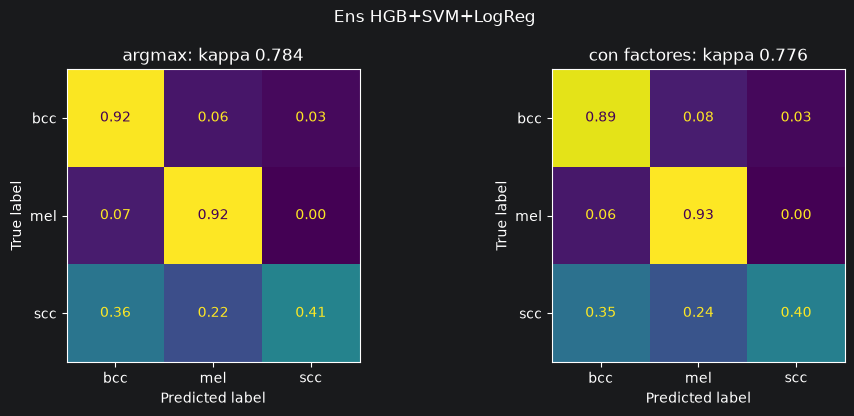

133

In [18]:
from itertools import product

TUNE_DECISION = True
W_GRID = np.round(np.arange(0.5, 3.01, 0.1), 2)        # factores a probar para BCC y SCC (MEL = 1)


def _oof_fold(spec, X, y, a, b):
    warnings.filterwarnings("ignore")
    Xa, Xb = _prep_fold(X, y, a, b, FINAL_RED)
    m = fit_head(*spec, Xa, y[a], is_projected(FINAL_RED))
    return b, predict_scores(m, Xb)


def oof_proba(spec):
    """Probabilidades out-of-fold (n_train, 3) con los mismos folds que la CV."""
    X = np.asarray(Xtr, dtype=np.float64)
    folds = list(skf.split(np.zeros(len(ytr)), ytr))
    out = Parallel(n_jobs=min(N_JOBS, len(folds)))(delayed(_oof_fold)(spec, X, ytr, a, b) for a, b in folds)
    P = np.zeros((len(ytr), len(CLASSES)))
    for b, Pb in out:
        P[b] = Pb
    return P


def apply_w(P, w):
    return np.argmax(P * np.asarray(w, dtype=float), axis=1)


def best_weights(P, y, fn=cohen_kappa_score):
    ref = CLASSES.index("mel")
    others = [j for j in range(len(CLASSES)) if j != ref]
    best_w = np.ones(len(CLASSES))
    best_s = fn(y, apply_w(P, best_w))
    for vals in product(W_GRID, repeat=len(others)):
        w = np.ones(len(CLASSES))
        w[others] = vals
        s = fn(y, apply_w(P, w))
        if s > best_s + 1e-9:
            best_w, best_s = w, s
    return best_w, best_s


DECISION_W = np.ones(len(CLASSES))
if TUNE_DECISION:
    P_oof = oof_proba(ALL_SPECS[best])
    k_arg = cohen_kappa_score(ytr, P_oof.argmax(1))
    DECISION_W, k_w = best_weights(P_oof, ytr)
    print(f"Modelo: {best}")
    print(f"Factores por clase: {dict(zip(CLASSES, DECISION_W.round(2)))}")
    print(f"CV out-of-fold: kappa {k_arg:.3f} (argmax) -> {k_w:.3f} (con factores)\n")

    P = probas[best]
    rows = []
    for lab, pr in [("argmax", preds[best]), ("con factores", apply_w(P, DECISION_W))]:
        lo, hi = boot_ci(yva, pr)
        m = mc_metrics(yva, P, pr)
        rows.append({"decisión": lab, "kappa": m["kappa"], "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]",
                     "bal_acc": m["bal_acc"], "f1_macro": m["f1_macro"], **{f"recall_{c}": m[f"recall_{c}"] for c in CLASSES}})
    dec_res = pd.DataFrame(rows).set_index("decisión")
    print(f"Val ({len(Xva)} imágenes), {best}:\n")
    print(dec_res.round(3).to_string())
    dec_res.round(4).to_csv(OUT_DIR / "val_decision_weights.csv")

    fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, (lab, pr) in zip(axs, [("argmax", preds[best]), ("con factores", apply_w(P, DECISION_W))]):
        ConfusionMatrixDisplay.from_predictions(yva, pr, labels=list(range(len(CLASSES))), display_labels=CLASSES,
                                                normalize="true", values_format=".2f", ax=ax, colorbar=False)
        ax.set_title(f"{lab}: kappa {cohen_kappa_score(yva, pr):.3f}")
    plt.suptitle(best); plt.tight_layout(); plt.show()

(OUT_DIR / "decision_weights.json").write_text(
    json.dumps({"model": best, "classes": CLASSES, "weights": DECISION_W.tolist()}, indent=2), encoding="utf-8")

### Matrices de confusión de todos los modelos (val, normalizadas por fila = recall de cada clase)

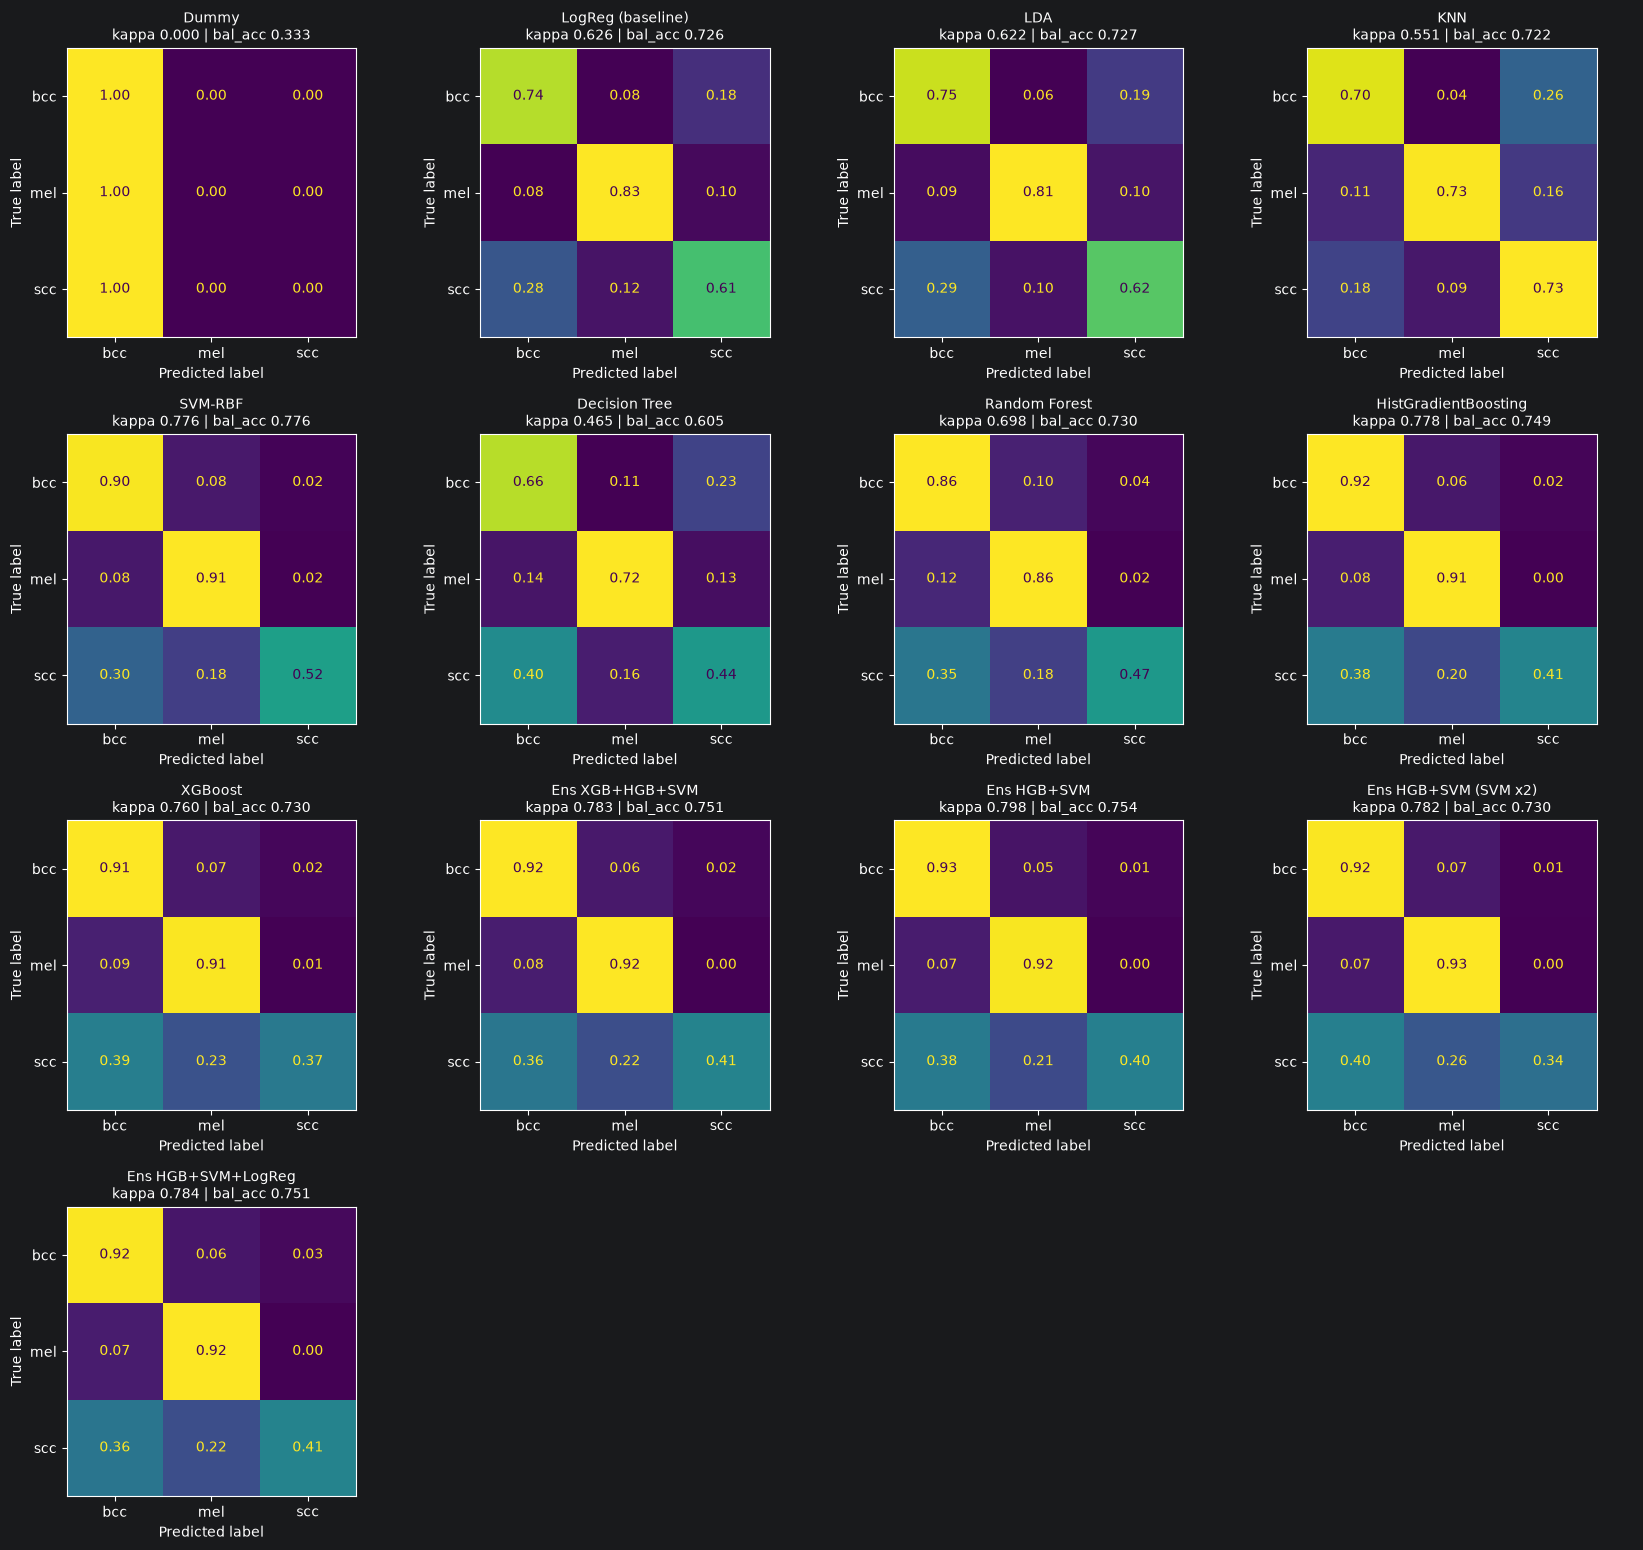

In [19]:
names = list(fitted)
nc = 4
nr = int(np.ceil(len(names) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(4.2 * nc, 3.9 * nr), squeeze=False)
for ax, name in zip(axs.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(yva, preds[name], labels=list(range(len(CLASSES))), display_labels=CLASSES,
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(f"{name}\nkappa {val_res.loc[name, 'kappa']:.3f} | bal_acc {val_res.loc[name, 'bal_acc']:.3f}", fontsize=10)
for ax in axs.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Mejor modelo (elegido por CV): detalle

Mejor modelo en CV: Ens HGB+SVM+LogReg

              precision    recall  f1-score   support

         bcc      0.844     0.916     0.879       498
         mel      0.926     0.922     0.924       678
         scc      0.709     0.415     0.523        94

    accuracy                          0.882      1270
   macro avg      0.826     0.751     0.775      1270
weighted avg      0.878     0.882     0.876      1270



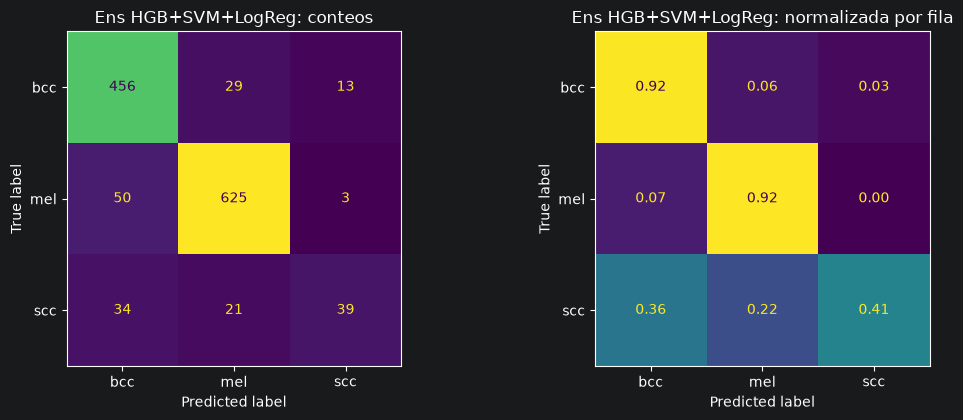

In [20]:
print(f"Mejor modelo en CV: {best}\n")
print(classification_report(yva, preds[best], target_names=CLASSES, digits=3))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, norm, fmt, title in [(axs[0], None, "d", "conteos"), (axs[1], "true", ".2f", "normalizada por fila")]:
    ConfusionMatrixDisplay.from_predictions(yva, preds[best], labels=list(range(len(CLASSES))), display_labels=CLASSES,
                                            normalize=norm, values_format=fmt, ax=ax, colorbar=False)
    ax.set_title(f"{best}: {title}")
plt.tight_layout(); plt.show()

### Curvas precision-recall (val)
Con clases desbalanceadas, la curva PR es más informativa que la ROC para la clase minoritaria: la ROC usa la tasa de
falsos positivos, que casi no se mueve porque SCC tiene muchísimos negativos (MEL + BCC); la PR usa la **precisión**,
que sí cae con cada falso positivo. El nivel del azar en PR es la **prevalencia** de la clase (línea discontinua),
no 0.5 como en la ROC.

- Izquierda: el mejor modelo, una curva por clase (one-vs-rest).
- Derecha: SCC para todos los modelos.
- El punto marca dónde cae la predicción actual (argmax), es decir, el recall y la precisión que se obtienen hoy.

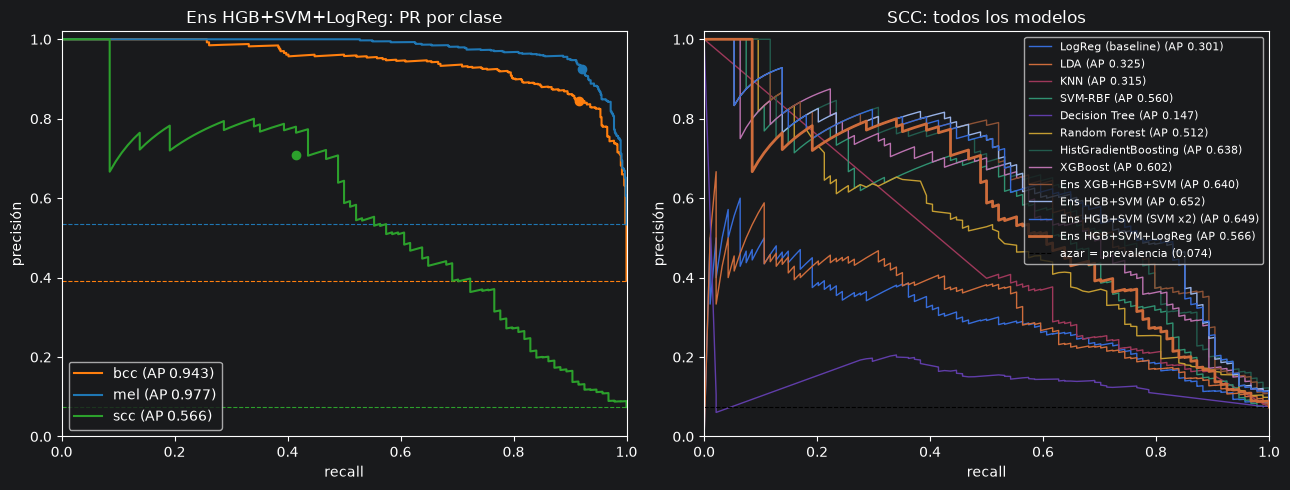

In [21]:
Yva = label_binarize(yva, classes=list(range(len(CLASSES))))
colors = {"mel": "#1f77b4", "bcc": "#ff7f0e", "scc": "#2ca02c"}
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

for j, c in enumerate(CLASSES):
    prec, rec, _ = precision_recall_curve(Yva[:, j], probas[best][:, j])
    ap = average_precision_score(Yva[:, j], probas[best][:, j])
    axs[0].plot(rec, prec, color=colors.get(c), label=f"{c} (AP {ap:.3f})")
    axs[0].axhline(Yva[:, j].mean(), color=colors.get(c), ls="--", lw=0.8)
    hit = preds[best] == j
    if hit.any():
        axs[0].plot(recall_score(Yva[:, j], hit), (Yva[hit, j]).mean(), "o", color=colors.get(c))
axs[0].set(xlabel="recall", ylabel="precisión", title=f"{best}: PR por clase", xlim=(0, 1), ylim=(0, 1.02))
axs[0].legend(loc="lower left")

j = CLASSES.index("scc")
for name in fitted:
    if name == "Dummy":
        continue
    prec, rec, _ = precision_recall_curve(Yva[:, j], probas[name][:, j])
    ap = average_precision_score(Yva[:, j], probas[name][:, j])
    axs[1].plot(rec, prec, lw=2 if name == best else 1, label=f"{name} (AP {ap:.3f})")
axs[1].axhline(Yva[:, j].mean(), color="k", ls="--", lw=0.8, label=f"azar = prevalencia ({Yva[:, j].mean():.3f})")
axs[1].set(xlabel="recall", ylabel="precisión", title="SCC: todos los modelos", xlim=(0, 1), ylim=(0, 1.02))
axs[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

### Guardar los modelos
Se guarda cada modelo final (entrenado con todo train) en `ml_results_multiclass_smote_pca_lda/models/` como un `.joblib` con el **pipeline completo**
(imputación → [selección | escalado → PCA/LDA] → [escalado] → modelo), más una copia del mejor como `best_model.joblib` y un `models_info.json`
con la lista de features (en orden), las etiquetas, el remuestreo usado, las métricas en val y las versiones de las
librerías. Los pipelines guardados no incluyen el sampler.
(`*.joblib` está en el `.gitignore`: no se suben a GitHub.)

Para usarlos después (por ejemplo con las features del test), hacen falta **las mismas versiones** de sklearn / xgboost:
```python
import json, joblib, pandas as pd
d = ROOT / "ml" / "ml_results_multiclass_smote_pca_lda" / "models"
info = json.load(open(d / "models_info.json", encoding="utf-8"))
model = joblib.load(d / "best_model.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]     # mismas columnas, mismo orden
pred = model.predict(X_test)                                    # 0 = bcc, 1 = mel, 2 = scc (orden de CLASSES)
```

In [22]:
TASK = "multiclass"
LABELS = dict(enumerate(CLASSES))
SELECTION = f"{FINAL_RED_NAME} {FINAL_RED}" if FINAL_RED is not None else "todas las features"

import json
import platform
from datetime import datetime

import joblib
import sklearn

MODEL_DIR = OUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
slug = lambda s: "".join(ch if ch.isalnum() else "_" for ch in s).strip("_").lower()

# cada archivo es el pipeline COMPLETO ya entrenado con todo train:
# imputación -> [selección top-K] -> [escalado] -> modelo. Recibe las features crudas (FEATS, en ese orden).
saved = {}
for name, pipe in fitted.items():
    if name == "Dummy":
        continue
    path = MODEL_DIR / f"{slug(name)}.joblib"
    joblib.dump(pipe, path, compress=3)
    saved[name] = path.name
joblib.dump(fitted[best], MODEL_DIR / "best_model.joblib", compress=3)

# comprobación: el modelo recargado predice exactamente lo mismo en val
assert (joblib.load(MODEL_DIR / "best_model.joblib").predict(Xva) == preds[best]).all()

try:
    import xgboost
    xgb_version = xgboost.__version__
except Exception:
    xgb_version = None

info = {
    "task": TASK,
    "created": datetime.now().isoformat(timespec="seconds"),
    "best_model": best,
    "files": {**saved, "best": "best_model.joblib"},
    "labels": LABELS,
    "feature_selection": SELECTION,
    "resampling": repr(SAMPLER),   # solo se usó al entrenar
    "n_features_in": len(FEATS),
    "features": FEATS,                                   # columnas de entrada, en este orden
    "train_csv": str(TRAIN_CSV),
    "val_metrics": val_res.reset_index().to_dict(orient="records"),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgb_version,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(MODEL_DIR / "models_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print(f"Modelos guardados en {MODEL_DIR}  (mejor: {best} -> best_model.joblib)\n")
for f in sorted(MODEL_DIR.glob("*")):
    print(f"  {f.name:<35s} {f.stat().st_size / 1e6:7.1f} MB")

Modelos guardados en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_multiclass_smote_pca_lda\models  (mejor: Ens HGB+SVM+LogReg -> best_model.joblib)

  best_model.joblib                      12.4 MB
  decision_tree.joblib                    0.5 MB
  ens_hgb_svm.joblib                     12.4 MB
  ens_hgb_svm__svm_x2.joblib             12.4 MB
  ens_hgb_svm_logreg.joblib              12.4 MB
  ens_xgb_hgb_svm.joblib                 13.7 MB
  histgradientboosting.joblib             3.2 MB
  knn.joblib                             25.3 MB
  lda.joblib                              3.1 MB
  logreg__baseline.joblib                 0.5 MB
  models_info.json                        0.0 MB
  random_forest.joblib                   11.5 MB
  svm_rbf.joblib                          9.7 MB
  xgboost.joblib                          1.8 MB


### ¿Qué features usa el mejor modelo?
Importancia por permutación en val (caída del **kappa** al barajar cada feature). Con top-K solo se permutan las K
seleccionadas. Con PCA / LDA se permutan las **features originales** (cada una afecta a todos los componentes), así que
la importancia sigue siendo interpretable aunque el modelo vea componentes.

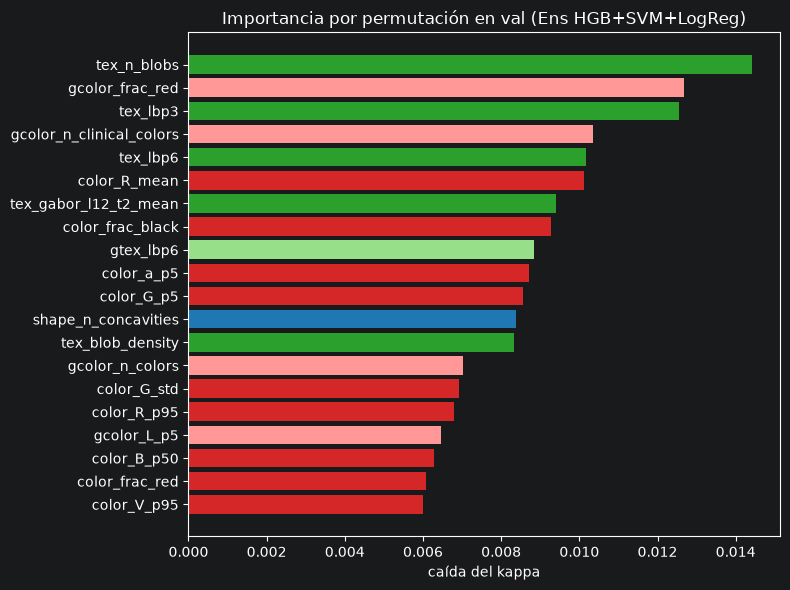

Importancia total por familia: {'color': 0.121, 'gcolor': -0.011, 'gtex': -0.05, 'shape': -0.001, 'tex': 0.102}


In [23]:
pipe = fitted[best]
if "sel" in pipe.named_steps:
    sel = pipe.named_steps["sel"].get_support()
    X_pi, est_pi, names_pi = pipe.named_steps["imp"].transform(Xva)[:, sel], pipe[2:], np.array(FEATS)[sel]
else:
    X_pi, est_pi, names_pi = pipe.named_steps["imp"].transform(Xva), pipe[1:], np.array(FEATS)
pi = permutation_importance(est_pi, X_pi, yva, scoring=make_scorer(cohen_kappa_score), n_repeats=5,
                            random_state=SEED, n_jobs=N_JOBS)
pi = pd.Series(pi.importances_mean, index=names_pi).sort_values(ascending=False)
pi.rename("importancia").to_csv(OUT_DIR / "permutation_importance_best.csv")
top = pi.head(20)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
plt.title(f"Importancia por permutación en val ({best})")
plt.xlabel("caída del kappa"); plt.tight_layout(); plt.show()
print("Importancia total por familia:", pi.groupby(lambda c: family(c)).sum().round(3).to_dict())

## 5. Control de sesgo: ¿se puede adivinar la clase solo con la resolución de la imagen?
Si la resolución original (que delata el dataset de origen: HAM10000, BCN20000, MSK...) ya predice bien la clase, parte
del rendimiento puede venir de la fuente y no de la lesión. Usa `processed/manifest.csv` (`orig_h`, `orig_w`).

In [24]:
man_path = ROOT / "processed" / "manifest.csv"
if not man_path.exists():
    print(f"No encuentro {man_path}: se omite este control.")
else:
    man = pd.read_csv(man_path).drop_duplicates("name").set_index("name")
    cols = ["orig_h", "orig_w"]
    m_tr, m_va = man.reindex(tr["name"])[cols].to_numpy(), man.reindex(va["name"])[cols].to_numpy()
    g = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED).fit(m_tr, ytr)
    p = g.predict(m_va)
    print(f"Solo con la resolución original -> val kappa {cohen_kappa_score(yva, p):.3f}, "
          f"bal_acc {balanced_accuracy_score(yva, p):.3f}\n")
    res_str = man.reindex(va["name"])["orig_w"].astype("Int64").astype(str) + "x" + \
              man.reindex(va["name"])["orig_h"].astype("Int64").astype(str)
    ct = pd.crosstab(res_str.to_numpy(), va["subtype"].to_numpy())
    print(ct.reindex(columns=CLASSES).loc[ct.sum(axis=1).sort_values(ascending=False).index].head(10).to_string())

    rows = []
    for r, idx in pd.Series(range(len(va)), index=res_str.to_numpy()).groupby(level=0):
        idx = idx.to_numpy()
        if len(idx) >= 30 and len(np.unique(yva[idx])) > 1:
            rows.append((r, len(idx), cohen_kappa_score(yva[idx], preds[best][idx]),
                         balanced_accuracy_score(yva[idx], preds[best][idx])))
    print(f"\n{best} por resolución (grupos con >= 30 imágenes):")
    print(pd.DataFrame(rows, columns=["res", "n", "kappa", "bal_acc"]).round(3).to_string(index=False))

No encuentro C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\processed\manifest.csv: se omite este control.


## 6. Modelo final para el test: reentrenar con train + val
Una vez decidido todo con la CV (parámetros, features, modelo o ensemble, factores de decisión) y comprobado en val, se
reentrena el **mismo** pipeline con **train + val** (25 % más de datos, y 94 SCC reales más). Val ya no puede evaluar este
modelo (lo ha visto), así que su rendimiento esperado es el de val o algo mejor.

Se guarda en `OUT_DIR/models/final_model_trainval.joblib` junto con `final_model_trainval.json` (features en orden,
etiquetas y factores de decisión). Para predecir el test:

```python
import json, joblib, numpy as np, pandas as pd
d = ROOT / "ml" / "<carpeta de resultados de este notebook>" / "models"
info = json.load(open(d / "final_model_trainval.json", encoding="utf-8"))
model = joblib.load(d / "final_model_trainval.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]          # mismas columnas, mismo orden
if hasattr(model, "predict_proba"):
    P = model.predict_proba(X_test)
else:                                                                # SVM sin probabilidades: softmax de decision_function
    d_ = model.decision_function(X_test); P = np.exp(d_ - d_.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
pred = np.argmax(P * np.array(info["decision_weights"]), axis=1)     # 0 = bcc, 1 = mel, 2 = scc
labels = [info["labels"][str(i)] for i in pred]
```

In [25]:
import joblib

FIT_TRAINVAL = True

if FIT_TRAINVAL:
    Xall = pd.concat([Xtr, Xva], ignore_index=True)
    yall = np.r_[ytr, yva]
    prep_all = make_prep(FINAL_RED, n_jobs=N_JOBS).fit(Xall, yall)
    head_all = fit_head(*ALL_SPECS[best], prep_all.transform(Xall), yall, is_projected(FINAL_RED))
    final_pipe = Pipeline(prep_all.steps + [s for s in head_all.steps if s[0] != "sampler"])

    MODEL_DIR = OUT_DIR / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_pipe, MODEL_DIR / "final_model_trainval.joblib", compress=3)
    final_info = {"model": best, "trained_on": f"train + val ({len(yall)} imágenes)",
                  "feature_selection": str(FINAL_RED_NAME), "params": best_params,
                  "decision_weights": DECISION_W.tolist(), "labels": dict(enumerate(CLASSES)), "features": FEATS,
                  "cv_kappa": float(res_cv.loc[best, "_main"]), "val_kappa": float(val_res.loc[best, "kappa"])}
    (MODEL_DIR / "final_model_trainval.json").write_text(json.dumps(final_info, indent=2, ensure_ascii=False, default=str),
                                                         encoding="utf-8")
    counts_all = pd.Series(yall).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES).to_dict()
    print(f"Modelo final: {best} | entrenado con {len(yall)} imágenes {counts_all}")
    print(f"factores de decisión: {dict(zip(CLASSES, DECISION_W.round(2)))}")
    print(f"guardado en {MODEL_DIR / 'final_model_trainval.joblib'}")

Modelo final: Ens HGB+SVM+LogReg | entrenado con 6352 imágenes {'bcc': 2491, 'mel': 3391, 'scc': 470}
factores de decisión: {'bcc': np.float64(0.7), 'mel': np.float64(1.0), 'scc': np.float64(0.7)}
guardado en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_multiclass_smote_pca_lda\models\final_model_trainval.joblib


## Notas y siguientes pasos
*(Rellenar después de ejecutar.)* Comparar con v4 (mismo remuestreo, sin PCA/LDA), v7 (mismas reducciones con RUS+SMOTE) y el resto
(`ml/ml_results_multiclass*/val_results.csv`).

- ¿Qué reducción gana en CV? ¿Con qué modelos ayuda PCA y con cuáles empeora?
- Nº de componentes de PCA: ¿mejora al subir de 10 → 30 → 60, o se estanca? (Si se estanca pronto, sobran features.)
- ¿Qué separa LDA en el scatter de val? (¿SCC queda entre MEL y BCC o solapado con alguna?)
- Recall de SCC con la mejor reducción frente a v5.